# 09 · Trades: how to bet on what you think, and what each bet costs

**The question.** Notebooks 03–08 say what CoreWeave's and SpaceX's bonds and stocks are pricing. If you agree with one part of the market and not another, what trade expresses that view? And since the bonds are 144A (sold only to institutions), how does a reader build the same bet from things they *can* buy? This is the "for entertainment" section of the post. Every trade is priced from real quotes, and every one has a scenario where it hurts.

**Short answer** (options: Nov 9, 2026 close; bonds: TRACE last trades, Nov 10; P&L at the Jan 19, 2029 option expiry; per $10,000 of bond face, or the same cash in Treasuries; options in 100-share contracts):
1. **You can build a CoreWeave bond, but not a SpaceX one** (§2, `09_build_your_own_bond.png`).
   - Treasuries plus sold put spreads that only lose if the stock nearly hits zero earn ~9.5–10% a year on CoreWeave, vs. the 144A bond's 14.6%. To match 14.6% you have to insure against a ~60% fall, which is stock risk, not default risk.
   - For SpaceX the same build earns ~5%, barely above Treasuries (4.6%), vs. the bond's 7.2%. The options market charges almost nothing to insure against a SpaceX default. So whatever SpaceX's extra yield pays for, it isn't default, which is the post's §8 point, here as a price.
2. **"Dilution, not default" (CoreWeave): the bond plus a sold $90 call** (§3). It makes ~$4,700 in a *dilution rescue* (bond alone ~$3,300) and cuts a default to ~−$1,070 (bond alone ~−$2,520). **The reader version is an iron condor:** Treasuries, sold $10/$5 put spreads, and sold $90/$135 call spreads. It makes ~$2,700 anywhere from $10 to $90, with every loss capped (§3–4, `09_coreweave_payoffs.png`).
3. **"Dilution, insured": add a $20 put to trade 1.** It makes money in all five scenarios, ~+$130 even in a default (§3). What it still loses to (a boom above ~$134, a late default, low recovery) is what the 15% yield pays for.
4. **For a bear, five $10 puts cost $1,150 and pay ~$3,350 in a default** (§4). Shorting the bond costs ~$3,200–4,000 if CoreWeave muddles through, because you pay its coupon.
5. **"Solvent but overvalued" (SpaceX)** (§5, `09_spacex_trades.png`):
   - Bond + $75 put − $250 call: paid ~$1,100 to set up, ~+$7,500 if SpaceX is worth our IPO post's ~$350B and still pays its bonds.
   - **The reader version is a "seagull"**: Treasuries + a $75/$25 put spread − a $250/$295 call spread. ~+$5,400 at $350B, ~+$500 if nothing changes, and every loss is capped.
6. **"Let Treasuries buy your put spread" (SpaceX): Treasuries + a $100/$25 put spread** (§5). It loses at most ~$725, and makes ~$6,700–6,800 at $350B *or* in distress. It's the cleanest bet in the notebook. The bond version (trade 5) does about the same, but loses its edge in distress.
7. **"Bonds paid, stock stalls" (SpaceX): bond − a $200 call** (§5) turns a 7.2% bond into ~20% a year if nothing changes. It has no good reader version, because SpaceX default insurance pays too little to fund one (point 1).
8. **"Homemade convertible": bond + a $150 call** (§6). A real convertible, like CoreWeave's 2033s, is the same two pieces glued together: holders give up ~6.75 points a year of coupon to own the call. Ours pays for the call up front instead. ~+$12,100 if AI wins, ~−$8,800 in distress. **The reader version (Treasuries + a $150/$295 call spread) beats it in every scenario**, by ~$300 if AI wins and by ~$6,700 in distress. SpaceX's ~2.6 points of extra yield doesn't cover its default risk inside a two-year option trade.
9. **Every reader version is built from three parts** (§7, `09_how_to_build_it.png`):
   - Treasuries replace the bond.
   - Sold deep put spreads replace its default risk.
   - Spreads replace naked options, so every loss is capped.

   §7 lists the exact orders and their break-evens.
10. **The post's seven trades, with payoff charts and yields** (§9, `09_post_*.png`). Measured as a yearly return on the cash put up: the CoreWeave build ~14.9% (bond 14.6%), the SpaceX build ~8.2% (bond 7.2%), trade 1 ~17.3%, the iron condor ~13.2%, SpaceX bond − $200 call ~20.0%, all if nothing changes; the seagull ~2.3%, because its options eat most of the Treasury interest.

| § | Question | Chart |
|---|---|---|
| 1 | How do we price a trade, and under which scenarios? | (tables) |
| 2 | Readers can't buy the bonds. Can they build them? | `09_build_your_own_bond.png` |
| 3 | CoreWeave: how do you bet "they'll pay, but by diluting"? | (table) |
| 4 | CoreWeave: how do you bet against it, and what does each trade look like? | `09_coreweave_trades.png`, `09_coreweave_payoffs.png` |
| 5 | SpaceX: how do you bet "solvent but overvalued"? | (table) |
| 6 | SpaceX: how do you bet on AI winning, and what does each trade look like? | `09_spacex_trades.png`, `09_spacex_payoffs.png` |
| 7 | How do you build each trade without the 144A bond? | `09_how_to_build_it.png` |
| 8 | What does a reader need to put these on? | (table) |
| 9 | The post's trades: what does each pay, and what yield is that? | `09_post_build.png`, `09_post_trade1.png` … `09_post_trade6.png` |

**Inputs:**
- Every Jan 2029 option on CoreWeave and SpaceX, with quoted closing bid/ask, from Market Data. Cached in `data/options/trades/`, separate from 01's snapshots that 06 uses.
- Bond prices from FINRA TRACE (last trades, read from each bond's FINRA page) for the same day or up to 3 days after (free-plan options are a day behind), in `data/trade_quotes.csv` with sources.
- Bond terms and recovery assumptions from `bonds.csv`.

**Outputs:** `data/trades.csv` and `data/trade_profiles.csv` (P&L by trade and scenario; reader trades' max gain/loss), `data/post_trades.csv` and `data/post_trade_profiles.csv` (§9, the post's trades with yields), all used by `research.ipynb`; the six `charts/09_*.png` of §2–7 and the seven `charts/09_post_*.png` of §9.

*Re-priced Nov 10: options at the Nov 9 close, bonds at Nov 10 TRACE last trades, the same date as the rest of the project.*

*Not investment advice. These are illustrations of how prices connect, priced from one day's quotes.*

## 1 · How do we price a trade, and under which scenarios?

**Why ask.** A trade is only "good" relative to a view. So we fix a handful of named scenarios for Jan 19, 2029, the longest-dated options available, and compute what each trade makes or loses in each one.

**Method, in plain language:**
- **Bond legs (institutions only):**
  - Buy $10,000 of face value at the TRACE closing price.
  - In Jan 2029 it's worth its price at the scenario's yield, or the `bonds.csv` recovery rate (40%) if it has defaulted.
  - Coupons collected along the way count.
- **Treasury legs (reader versions):** the same cash the bond would cost goes into Treasuries maturing around Jan 2029. These are available at any broker or TreasuryDirect. It earns the Treasury rate and also serves as the collateral for any sold spreads.
- **Option legs:**
  - Every price is a real quote. You buy at the ask and sell at the bid, so the bid-ask spread is a real cost.
  - At expiry, a call pays the stock price above its strike, and a put pays the strike above the stock price.
  - A **spread** is two options at different strikes, one bought and one sold. It caps both what you can make and what you can lose, so every reader trade has a known worst case.
- **The options market's odds** of the stock ending above or below a price come straight from quoted prices. A put that pays $1 more for every $1 the strike rises is a sure thing. One that pays $0.25 more means a ~25% chance of ending below that strike. That's the same idea as 06 §8's crash odds, without the smile model.
- **No 2030 options exist yet, and CoreWeave has no 2028 bonds.** So "2030 calls on 2028 bonds" becomes Jan 2029 options on the June 2030 notes.

**Scenarios** (assumptions, not forecasts; each one is tied to a notebook result):
- **CoreWeave:**
  - *Shortage lasts:* the stock goes back near its April 2026 level, and the bonds are priced as a much better credit.
  - *Dilution rescue:* CoreWeave sells ~40% of itself to pay the 2028 wall (08 §5). The stock is $30 and the bonds are fine.
  - *Muddle through:* nothing changes.
  - *Slow squeeze:* no default yet, but priced for one (35% yield, stock $12).
  - *Glut and default:* old-GPU rents fall like H100s' did (08 §3).
- **SpaceX:**
  - *AI wins:* the stock more than doubles, and the bonds tighten.
  - *AI wins on borrowed money:* the stock rises, but $300B+ of secured GPU debt now ranks ahead of the notes (06 §6), so their yields rise. The 2056s rise more, because they sit behind that debt for 30 years.
  - *Muddle through:* nothing changes.
  - *Worth $350B, solvent:* the stock falls to what our SpaceX IPO post said it's worth (~$26), but Starlink keeps paying the bonds.
  - *Primed:* the borrowing comes, but the AI payoff doesn't.
  - *Distress.*

In [1]:
from pathlib import Path
import os, requests
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from common import INK, INK2, MUTED, AXIS, BOND, EQUITY, source_note, treasury_yield, bond_price, ytm, bs_call, bs_put

plt.rcParams['text.parse_math'] = False
CHARTS, OPT_DIR = Path('charts'), Path('data/options/trades')
EXPIRY = pd.Timestamp('2029-01-19')                       # the longest-dated listed options
FACE = 10_000                                             # bond position: $10,000 of face value
BORROW = 0.02                                             # assumption: yearly fee to borrow a bond to short it
REFRESH = False                                           # True pulls a fresh chain (~170 Market Data credits for both)

def chain(t):
    """Every Jan 2029 option on ticker t, with quoted bid/ask. Cached one file per quote date in data/options/trades/
    (kept apart from 01's snapshots, which 06 reads)."""
    have = sorted(OPT_DIR.glob(f'{t}_*.csv'))
    if have and not REFRESH:
        return pd.read_csv(have[-1], parse_dates=['expiration', 'updated'])
    if 'MARKETDATA_TOKEN' not in os.environ:   # same .env loader as 01
        for line in Path('.env').read_text().splitlines():
            if '=' in line and not line.lstrip().startswith('#'):
                k, v = line.split('=', 1); os.environ.setdefault(k.strip(), v.strip().strip('"\''))
    r = requests.get(f'https://api.marketdata.app/v1/options/chain/{t}/', params={'expiration': f'{EXPIRY:%Y-%m-%d}'},
                     headers={'Authorization': f"Bearer {os.environ['MARKETDATA_TOKEN']}"}, timeout=60)
    j = r.json(); assert j.get('s') == 'ok', j.get('errmsg')
    d = pd.DataFrame({k: v for k, v in j.items() if isinstance(v, list)})
    d['expiration'] = pd.to_datetime(d.expiration, unit='s').dt.normalize()
    d['updated'] = pd.to_datetime(d.updated, unit='s')
    OPT_DIR.mkdir(parents=True, exist_ok=True)
    d.to_csv(OPT_DIR / f'{t}_{d.updated.max():%Y-%m-%d}.csv', index=False)
    return d

OPT = {t: chain(t) for t in ['CRWV', 'SPCX']}
SPOT = {t: d.underlyingPrice.iloc[0] for t, d in OPT.items()}
AS_OF = pd.Timestamp(OPT['CRWV'].updated.max().date())
assert all(d.updated.max().date() == AS_OF.date() for d in OPT.values()), 'option snapshots are from different days'

# Bond prices: FINRA TRACE end-of-day closes, hand-read into data/trade_quotes.csv (source per row), same day as the options
tq = pd.read_csv('data/trade_quotes.csv', parse_dates=['as_of'])
# free-plan options are a day behind, so take the bond quotes from the same day or up to 3 days after
tq = tq[(tq.as_of >= AS_OF) & (tq.as_of <= AS_OF + pd.Timedelta(days=3))].sort_values('as_of').groupby('bond_id').tail(1)
PX, BOND_DATE = tq.set_index('bond_id').price, tq.as_of.max()
assert len(PX) == 3, f'add TRACE quotes from {AS_OF:%Y-%m-%d} to 3 days after to data/trade_quotes.csv'
T = (EXPIRY - AS_OF).days / 365.25                        # option life, years
R_CC = np.log(1 + treasury_yield(AS_OF, T) / 100)         # continuous risk-free rate to expiry
bonds = pd.read_csv('bonds.csv', parse_dates=['maturity']).set_index('bond_id')
NOW_Y = {b: ytm(PX[b], bonds.loc[b, 'coupon'], (bonds.loc[b, 'maturity'] - AS_OF).days / 365.25) for b in PX.index}

def quote(t, kind, K, side):
    """Quoted Jan 2029 option: pay the ask to buy, receive the bid to sell."""
    q = OPT[t].query('side == @kind and strike == @K').iloc[0]
    return q.ask if side == 'buy' else q.bid

def odds(t, K, below=True):
    """The options market's odds the stock ends below (or above) K in Jan 2029, read straight off quoted prices:
    how fast put prices rise (or call prices fall) per $1 of strike, across strikes ~10% either side of K, grown at
    the risk-free rate. Below uses puts, above uses calls: out-of-the-money options have the tighter quotes."""
    o = OPT[t].query('side == @s', local_dict={'s': 'put' if below else 'call'}).set_index('strike')['mid'].sort_index()
    k = o.index
    lo = k[k <= 0.9 * K].max() if (k <= 0.9 * K).any() else k.min()   # at the edge of the chain, use the last strike
    hi = k[k >= 1.1 * K].min() if (k >= 1.1 * K).any() else k.max()
    return np.exp(R_CC * T) * abs(o[hi] - o[lo]) / (hi - lo)

# check: the odds move the right way with the strike and stay between 0 and 1
for t, ks in {'CRWV': [10, 20, 40], 'SPCX': [30, 75, 100]}.items():
    o = [odds(t, k) for k in ks]
    assert all(0 < a < b < 1 for a, b in zip(o, o[1:])), (t, o)
for t, ks in {'CRWV': [70, 90, 110], 'SPCX': [150, 200, 250]}.items():
    o = [odds(t, k, below=False) for k in ks]
    assert all(1 > a > b > 0 for a, b in zip(o, o[1:])), (t, o)

def bond_leg(bid, sc, short=False):
    """P&L to Jan 2029 on FACE of a bond: price change + coupons (or recovery if it defaults). Shorts pay coupons and a borrow fee."""
    b, p0 = bonds.loc[bid], PX[bid]
    left = (b.maturity - EXPIRY).days / 365.25
    end = 100 * b.assumed_recovery if sc['default'] else bond_price(sc['y'][bid], b.coupon, left)
    pnl = FACE * ((end - p0) + b.coupon * T) / 100
    return -pnl - BORROW * FACE * p0 / 100 * T if short else pnl

def cash_leg(amount):
    """Interest on cash set aside (e.g. to secure sold puts), at the Treasury rate to expiry."""
    return amount * (np.exp(R_CC * T) - 1)

def opt_leg(t, kind, K, n, sc):
    """P&L at expiry of n contracts (100 shares each); n > 0 buys at the ask, n < 0 sells at the bid."""
    S = sc['stock']
    pay = max(S - K, 0) if kind == 'call' else max(K - S, 0)
    return 100 * n * (pay - quote(t, kind, K, 'buy' if n > 0 else 'sell'))

print(f'Prices: options {AS_OF:%b %-d, %Y} close; bonds TRACE last trade {BOND_DATE:%b %-d, %Y}. Option life {T:.2f} years; Treasury rate {R_CC:.2%}.')
print(f'Spot: CoreWeave ${SPOT["CRWV"]:.2f}, SpaceX ${SPOT["SPCX"]:.2f}. ' + '; '.join(f'{b} {PX[b]:.2f} ({NOW_Y[b]:.1f}%)' for b in PX.index))

Prices: options Nov 9, 2026 close; bonds TRACE last trade Nov 10, 2026. Option life 2.20 years; Treasury rate 4.46%.
Spot: CoreWeave $49.00, SpaceX $142.12. CRWV_9.25_2030 85.50 (14.6%); SPCX_5.350_2031 92.74 (7.2%); SPCX_6.650_2056 84.28 (8.0%)


In [2]:
# Scenarios at Jan 19 2029 (assumptions, not forecasts). Yields are each bond's yield for its remaining life then.
C, S31, S56 = 'CRWV_9.25_2030', 'SPCX_5.350_2031', 'SPCX_6.650_2056'
SPX_350B = round(350 / (2003.07 / 147.49), 2)              # the SpaceX IPO post's $350B, per share (Oct 23 market cap / price)
SCEN = {
 'CRWV': {
  'Shortage lasts':   {'stock': 120, 'default': False, 'y': {C: 8.0}},    # back near its Apr 2026 high; credit improves
  'Dilution rescue':  {'stock': 30,  'default': False, 'y': {C: 11.0}},   # sells ~40% of the company; 2028 wall paid (08 §5)
  'Muddle through':   {'stock': round(SPOT['CRWV']), 'default': False, 'y': {C: round(NOW_Y[C], 1)}},  # nothing changes
  'Slow squeeze':     {'stock': 12,  'default': False, 'y': {C: 35.0}},   # not defaulted yet, but priced for it
  'Glut and default': {'stock': 1,   'default': True},                    # rents fall like H100s' (08 §3)
 },
 'SPCX': {
  'AI wins':                   {'stock': 300, 'default': False, 'y': {S31: 6.0, S56: 6.5}},
  'AI wins on borrowed money': {'stock': 250, 'default': False, 'y': {S31: 9.0, S56: 11.0}},   # $300B+ of secured GPU debt ranks ahead (06 §6)
  'Muddle through':            {'stock': round(SPOT['SPCX']), 'default': False, 'y': {b: round(NOW_Y[b], 1) for b in (S31, S56)}},
  'Worth $350B, solvent':      {'stock': SPX_350B, 'default': False, 'y': {S31: 7.5, S56: 8.5}},  # the IPO post's value; Starlink pays the bonds
  'Primed':                    {'stock': 90,  'default': False, 'y': {S31: 10.0, S56: 12.0}},  # the borrowing comes, the AI payoff doesn't
  'Distress':                  {'stock': 5,   'default': True},
 }}
pd.DataFrame([{'ticker': t, 'scenario': k, 'stock': v['stock'], 'default': v['default'], **{f'yield {b}': y for b, y in v.get('y', {}).items()}}
              for t, s in SCEN.items() for k, v in s.items()]).set_index(['ticker', 'scenario'])

stock  default  yield CRWV_9.25_2030  \
ticker scenario                                                           
CRWV   Shortage lasts             120.00    False                   8.0   
       Dilution rescue             30.00    False                  11.0   
       Muddle through              49.00    False                  14.6   
       Slow squeeze                12.00    False                  35.0   
       Glut and default             1.00     True                   NaN   
SPCX   AI wins                    300.00    False                   NaN   
       AI wins on borrowed money  250.00    False                   NaN   
       Muddle through             142.00    False                   NaN   
       Worth $350B, solvent        25.77    False                   NaN   
       Primed                      90.00    False                   NaN   
       Distress                     5.00     True                   NaN   

                                  yield SPCX_5.350_2031  yield SPCX_6.650_2056  
ticker scenario                                                                 
CRWV   Shortage lasts                               NaN                    NaN  
       Dilution rescue                              NaN                    NaN  
       Muddle through                               NaN                    NaN  
       Slow squeeze                                 NaN                    NaN  
       Glut and default                             NaN                    NaN  
SPCX   AI wins                                      6.0                    6.5  
       AI wins on borrowed money                    9.0                   11.0  
       Muddle through                               7.2                    8.0  
       Worth $350B, solvent                         7.5                    8.5  
       Primed                                      10.0                   12.0  
       Distress                                     NaN                    NaN

In [3]:
BOND_ONLY = 'Just the bond'
CASH = {'CRWV': FACE * PX[C] / 100, 'SPCX': FACE * PX[S31] / 100}   # a reader puts what the bond would cost into Treasuries

# Reader trades: Treasuries + listed options only, every loss capped. Legs are (kind, strike, contracts): + buys at the ask, − sells at the bid.
READER = {
 'CRWV': {
  "R. Reader's bond: Treasuries + sell 10 $10/$5 put spreads": [('put', 10, -10), ('put', 5, 10)],
  "1R. Iron condor: reader's bond + sell 2 $90/$135 call spreads": [('put', 10, -10), ('put', 5, 10), ('call', 90, -2), ('call', 135, 2)],
  '3. Default insurance (anyone): buy 5 $10 puts': [('put', 10, 5)],
 },
 'SPCX': {
  '4R. Seagull: Treasuries + buy a $75/$25 put spread + sell a $250/$295 call spread': [('put', 75, 1), ('put', 25, -1), ('call', 250, -1), ('call', 295, 1)],
  '5R. Let Treasuries buy your put spread: Treasuries + buy a $100/$25 put spread': [('put', 100, 1), ('put', 25, -1)],
  '7R. Treasury convertible: Treasuries + buy a $150/$295 call spread': [('call', 150, 1), ('call', 295, -1)],
 }}
CASH_FREE = {'3. Default insurance (anyone): buy 5 $10 puts'}            # a plain put purchase: no Treasury leg

def reader_leg(t, name, sc):
    """P&L at expiry of a reader trade: Treasury interest on CASH[t] plus each option leg."""
    return (0 if name in CASH_FREE else cash_leg(CASH[t])) + sum(opt_leg(t, k, K, n, sc) for k, K, n in READER[t][name])

def mark(t, name, S, tau):
    """A reader trade's P&L if closed with tau years left, at stock price S, if every option keeps its quoted volatility
    (Black-Scholes at each strike's own implied volatility). tau = 0 is the expiry payoff."""
    v = 0 if name in CASH_FREE else CASH[t] * (np.exp(R_CC * (T - tau)) - 1)
    for k, K, n in READER[t][name]:
        q = OPT[t].query('side == @k and strike == @K').iloc[0]
        now = ((bs_call if k == 'call' else bs_put)(S, K, tau, R_CC, q.iv) if tau > 0
               else max(S - K, 0) if k == 'call' else max(K - S, 0))
        v += 100 * n * (now - quote(t, k, K, 'buy' if n > 0 else 'sell'))
    return v

# check: marked today at today's price, a reader trade is down roughly its bid-ask cost, not more
for t in READER:
    for name, legs in READER[t].items():
        half = sum(100 * abs(n) * (q.ask - q.bid) for k, K, n in legs for q in [OPT[t].query('side == @k and strike == @K').iloc[0]])
        assert abs(mark(t, name, SPOT[t], T)) < half + 150, (t, name, mark(t, name, SPOT[t], T), half)

R_ = lambda t, name: (lambda s: reader_leg(t, name, s))
TRADES = {
 'CRWV': {
  BOND_ONLY: lambda s: bond_leg(C, s),
  "R. Reader's bond: Treasuries + sell 10 $10/$5 put spreads": R_('CRWV', "R. Reader's bond: Treasuries + sell 10 $10/$5 put spreads"),
  '1. Dilution, not default: bond + sell 1 $90 call': lambda s: bond_leg(C, s) + opt_leg('CRWV', 'call', 90, -1, s),
  "1R. Iron condor: reader's bond + sell 2 $90/$135 call spreads": R_('CRWV', "1R. Iron condor: reader's bond + sell 2 $90/$135 call spreads"),
  '2. Dilution, insured: bond + buy 1 $20 put + sell 1 $90 call': lambda s: bond_leg(C, s) + opt_leg('CRWV', 'put', 20, 1, s) + opt_leg('CRWV', 'call', 90, -1, s),
  '3. Default insurance (anyone): buy 5 $10 puts': R_('CRWV', '3. Default insurance (anyone): buy 5 $10 puts'),
  'Dropped: short the bond': lambda s: bond_leg(C, s, short=True),   # §4, for comparison; not charted
 },
 'SPCX': {
  BOND_ONLY: lambda s: bond_leg(S31, s),
  '4. Solvent but overvalued: bond + buy 1 $75 put + sell 1 $250 call': lambda s: bond_leg(S31, s) + opt_leg('SPCX', 'put', 75, 1, s) + opt_leg('SPCX', 'call', 250, -1, s),
  '4R. Seagull: Treasuries + buy a $75/$25 put spread + sell a $250/$295 call spread': R_('SPCX', '4R. Seagull: Treasuries + buy a $75/$25 put spread + sell a $250/$295 call spread'),
  '5. Let the bond buy your put: bond + buy 1 $100 put': lambda s: bond_leg(S31, s) + opt_leg('SPCX', 'put', 100, 1, s),
  '5R. Let Treasuries buy your put spread: Treasuries + buy a $100/$25 put spread': R_('SPCX', '5R. Let Treasuries buy your put spread: Treasuries + buy a $100/$25 put spread'),
  '6. Bonds paid, stock stalls: bond + sell 1 $200 call': lambda s: bond_leg(S31, s) + opt_leg('SPCX', 'call', 200, -1, s),
  '7. Homemade convertible: bond + buy 1 $150 call': lambda s: bond_leg(S31, s) + opt_leg('SPCX', 'call', 150, 1, s),
  '7R. Treasury convertible: Treasuries + buy a $150/$295 call spread': R_('SPCX', '7R. Treasury convertible: Treasuries + buy a $150/$295 call spread'),
  'Dropped: Musk maximalist, buy 1 $150 call + short the 2056 bonds': lambda s: opt_leg('SPCX', 'call', 150, 1, s) + bond_leg(S56, s, short=True),  # §6; not charted
 }}
pnl = {t: pd.DataFrame({name: {k: f(sc) for k, sc in SCEN[t].items()} for name, f in TRADES[t].items()}).T for t in TRADES}
TR = lambda t, prefix: next(n for n in pnl[t].index if n.startswith(prefix))   # look a trade up by its number, e.g. TR('SPCX', '5R.')

legs = pd.DataFrame([(f'{"CoreWeave" if t == "CRWV" else "SpaceX"} Jan 2029 ${K} {k}', quote(t, k, K, 'buy'), quote(t, k, K, 'sell'), OPT[t].query('side == @k and strike == @K').iloc[0].openInterest)
                     for t, ks in {'CRWV': [('call', 90), ('call', 135), ('put', 5), ('put', 10), ('put', 20)],
                                   'SPCX': [('put', 25), ('put', 75), ('put', 100), ('call', 150), ('call', 200), ('call', 250), ('call', 295)]}.items() for k, K in ks],
                    columns=['option', 'ask (you pay)', 'bid (you get)', 'open interest']).set_index('option')
out = pd.concat({t: p.stack().rename('pnl') for t, p in pnl.items()}).reset_index()
out.columns = ['ticker', 'trade', 'scenario', 'pnl']
out.to_csv('data/trades.csv', index=False)          # handoff to research.ipynb
legs

,ask (you pay),bid (you get),open interest
option,,,
CoreWeave Jan 2029 $90 call,16.45,14.45,452
CoreWeave Jan 2029 $135 call,10.45,9.10,1724
CoreWeave Jan 2029 $5 put,1.00,0.90,4248
CoreWeave Jan 2029 $10 put,2.30,2.00,1586
CoreWeave Jan 2029 $20 put,6.95,5.40,4017
SpaceX Jan 2029 $25 put,1.08,0.80,21081
SpaceX Jan 2029 $75 put,9.90,8.55,1291
SpaceX Jan 2029 $100 put,17.60,17.10,6451
SpaceX Jan 2029 $150 call,46.90,45.90,6707


## 2 · Readers can't buy the bonds. Can they build them?

**Why ask.** Every CoreWeave and SpaceX bond here is 144A: sold only to "qualified institutional buyers". A reader who wants "CoreWeave's 15%" can't just buy it. But finance has a well-known identity for this (it's the Merton model from 05, run backwards): **a risky bond = a safe bond − insurance against the company failing.** Readers can buy the safe bond (Treasuries). And they can *sell* the insurance, as a put spread on the stock.

**Method.**
- Put what the bond would cost into Treasuries.
- Sell put spreads: sell a put at one strike and buy one at half that strike.
  - The premium you collect is your "credit spread", the extra coupon over Treasuries.
  - The spread's maximum loss is your "loss in default".
- Size the number of spreads so that maximum loss equals what the bond loses in a default (price → 40% recovery).
- Then compare the yearly return if nothing goes wrong against the bond's yield.

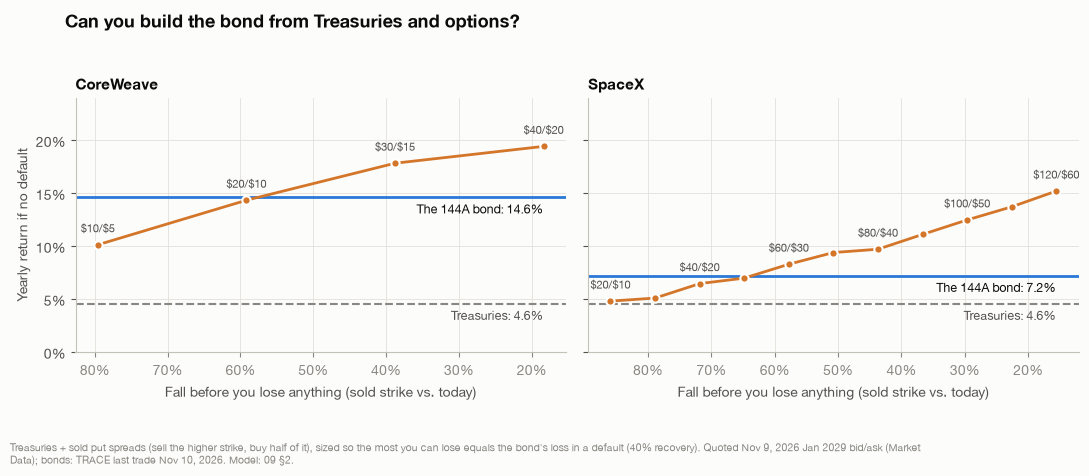

In [4]:
import matplotlib.ticker as mticker
TSY_Y = np.exp(R_CC) - 1                                    # Treasury yield to Jan 2029, as a yearly rate

def manufactured(t, bid, hi, lo):
    """Yearly return of 'Treasuries + sold hi/lo put spreads', sized so the most you can lose equals what the bond
    loses in a default (price → recovery). The bond's cost sits in Treasuries; the spreads' premium is the extra 'coupon'."""
    cost = FACE * PX[bid] / 100
    loss = cost - FACE * bonds.loc[bid, 'assumed_recovery']
    credit = quote(t, 'put', hi, 'sell') - quote(t, 'put', lo, 'buy')
    if credit <= 0: return np.nan
    n = loss / (100 * (hi - lo - credit))
    return (1 + (cost * (np.exp(R_CC * T) - 1) + n * 100 * credit) / cost) ** (1 / T) - 1

ks = lambda t: [k for k in OPT[t].query('side == "put"').strike if k / 2 in set(OPT[t].strike) and k <= 0.9 * SPOT[t]]   # at least 10% below today: insurance, not a stock bet
build = pd.concat({t: pd.DataFrame([{'sold strike': k, 'fall to reach it': 1 - k / SPOT[t], 'odds below': odds(t, k),
                                     'manufactured yield': manufactured(t, b, k, k / 2)} for k in ks(t)]).set_index('sold strike')
                   for t, b in [('CRWV', C), ('SPCX', S31)]})
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for ax, (t, b, name) in zip(axes, [('CRWV', C, 'CoreWeave'), ('SPCX', S31, 'SpaceX')]):
    d = build.loc[t].dropna()
    ax.plot(100 * d['fall to reach it'], 100 * d['manufactured yield'], '-o', color=EQUITY, lw=2, ms=6, mec='white', mew=1.5, zorder=3)
    for k, r in d.iloc[::max(1, len(d) // 4)].iterrows():   # label a few spreads, not every point
        ax.annotate(f'${k:g}/${k / 2:g}', (100 * r['fall to reach it'], 100 * r['manufactured yield']), xytext=(0, 9),
                    textcoords='offset points', ha='center', fontsize=8, color=INK2)
    ax.axhline(NOW_Y[b], color=BOND, lw=2)
    ax.text(100 * d['fall to reach it'].min(), NOW_Y[b] - 0.4, f'The 144A bond: {NOW_Y[b]:.1f}%', color=INK, fontsize=9, va='top', ha='right')
    ax.axhline(100 * TSY_Y, color=MUTED, lw=1.5, ls='--')
    ax.text(100 * d['fall to reach it'].min(), 100 * TSY_Y - 0.4, f'Treasuries: {100 * TSY_Y:.1f}%', color=INK2, fontsize=9, va='top', ha='right')
    ax.set_title(name, loc='left', fontsize=11)
    ax.set_xlabel('Fall before you lose anything (sold strike vs. today)')
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
    ax.invert_xaxis()
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:.0f}%'))
axes[0].set_ylabel('Yearly return if no default')
axes[0].set_ylim(0, 24)
fig.suptitle("Can you build the bond from Treasuries and options?", x=0.06, ha='left', fontsize=13, fontweight='bold')
source_note(fig, f'Treasuries + sold put spreads (sell the higher strike, buy half of it), sized so the most you can lose equals the bond\'s loss in a default '
                 f'(40% recovery). Quoted {AS_OF:%b %-d, %Y} Jan 2029 bid/ask (Market Data); bonds: TRACE last trade {BOND_DATE:%b %-d, %Y}. Model: 09 §2.')
fig.tight_layout(rect=(0, 0.06, 1, 0.95))
fig.savefig(CHARTS / '09_build_your_own_bond.png', dpi=200, bbox_inches='tight')
plt.show()
build.style.format({'fall to reach it': '{:.0%}', 'odds below': '{:.0%}', 'manufactured yield': '{:.1%}'}, na_rep='no premium')

**What this shows** (`charts/09_build_your_own_bond.png` and the table above):
- **CoreWeave: you can build most of the bond, if you accept stock-like risk.**
  - The bond-like version only loses if CoreWeave nearly hits zero: sold $10 puts, bought $5 puts, an ~80% fall before you lose anything. It earns ~9.5–10% a year, vs. 14.6% on the 144A bond.
  - To match the bond you have to sell the $20/$10 spread (~14.3%), which loses if CoreWeave falls ~59%; the options market gives that ~45% odds. Plenty of non-default paths get there (*dilution rescue* is $30).
  - So the 144A wall costs a reader ~5 points a year of yield for the same "default only" risk. Part of that is the options' bid-ask spread. Part is that bondholders are paid for risks the stock market doesn't insure: low recovery, and timing (03 §5).
- **SpaceX: you can't build the bond.**
  - The deep put spreads that only lose in a near-default pay almost nothing: ~5%, vs. 4.6% on Treasuries. The $10/$5 spread pays *nothing* after the bid-ask spread.
  - To beat the bond's 7.2% you have to insure against a ~60% fall ($50/$25 earns ~7.0%, $60/$30 ~8.3%), and SpaceX at $60 is a very different company from SpaceX in default.
  - **This is the post's §8 finding in trade form:** the options market prices SpaceX default near zero (06 §7 found ~1bp). So the bond's ~2.6 points over Treasuries pay for something no listed option insures: priming, illiquidity, new supply.
- **So the reader versions below use Treasuries + options.** For CoreWeave the sold $10/$5 put spreads stand in for the bond (the "reader's bond"). For SpaceX, Treasuries alone stand in, because the bond's extra yield isn't for default.

**Next:** with that toolkit, the CoreWeave trades.

## 3 · CoreWeave: how do you bet "they'll pay, but by diluting"?

**Why ask.** 08 §5 found that selling stock can cover CoreWeave's 2028 wall at today's price, at the cost of a much bigger share count. If that's what happens, the bonds get paid and the stock goes nowhere. That's the trade: **own the bond, sell the upside.**

**The trades:**
- **Trade 1 (institutional): buy $10,000 of the 9.25% June 2030 notes, sell one Jan 2029 $90 call.**
  - The $90 strike is just above what Nvidia paid ($87.20).
  - The call pays $14.45 a share, because options price ~90% yearly swings.
  - You keep that $1,445 unless CoreWeave is above $90 in Jan 2029.
- **Trade 1R (readers): an iron condor.** Combine:
  - the "reader's bond": Treasuries + sell ten $10/$5 put spreads;
  - "sell the upside": sell two $90/$135 call spreads.

  An iron condor is the options market's standard "this stock stays in a range" bet. Here the range has a meaning: above default, below a boom.
- **Trade 2: trade 1 plus one $20 put.** The call's premium pays for the put, which protects against a collapse before Jan 2029. In options jargon this is a "collar" around the bond.

In [5]:
cw, sx = pnl['CRWV'], pnl['SPCX']
T1, T1R, T2, RB = TR('CRWV', '1.'), TR('CRWV', '1R.'), TR('CRWV', '2.'), TR('CRWV', 'R.')
call90, put20 = quote('CRWV', 'call', 90, 'sell'), quote('CRWV', 'put', 20, 'buy')
be1 = 90 + call90                                                   # above this, trade 1 trails the bond alone
be2 = 90 + (bond_leg(C, SCEN['CRWV']['Shortage lasts']) + 100 * (call90 - put20)) / 100   # trade 2 turns negative above this
ps_cr = quote('CRWV', 'put', 10, 'sell') - quote('CRWV', 'put', 5, 'buy')
cs_cr = quote('CRWV', 'call', 90, 'sell') - quote('CRWV', 'call', 135, 'buy')
rb_ann = (1 + cw.loc[RB, 'Muddle through'] / CASH['CRWV']) ** (1 / T) - 1
be1r = 90 + (cw.loc[T1R, 'Muddle through']) / 200                   # 1R breaks even this far above $90 (2 call spreads = $200 per $1)
print(f'Trade 1 collects ${100 * call90:,.0f}; it trails the bond alone above ${be1:.0f} (options-market odds {odds("CRWV", be1, below=False):.0%}).')
print(f'Trade 2 adds a $20 put for ${100 * put20:,.0f}: net ${100 * (call90 - put20):,.0f} collected; it loses money only above ~${be2:.0f} '
      f'(odds {odds("CRWV", be2, below=False):.0%}).')
print(f"Reader's bond: ${CASH['CRWV']:,.0f} in Treasuries + 10 $10/$5 put spreads at ${ps_cr:.2f} (${1000 * ps_cr:,.0f}). "
      f"{rb_ann:.1%} a year if CoreWeave ends above $10, vs. the bond's {NOW_Y[C]:.1f}%; most it can lose ${-cw.loc[RB].min():,.0f}, vs. the bond's ${-cw.loc[BOND_ONLY].min():,.0f} in a default.")
print(f'1R adds 2 $90/$135 call spreads at ${cs_cr:.2f} (${200 * cs_cr:,.0f}). It loses money above ~${be1r:.0f} (odds {odds("CRWV", be1r, below=False):.0%}); '
      f'the most it can lose there is ${-mark("CRWV", T1R, 200, 0):,.0f}.')
cw.loc[[BOND_ONLY, RB, T1, T1R, T2]].round(0)

Trade 1 collects $1,445; it trails the bond alone above $104 (options-market odds 16%).
Trade 2 adds a $20 put for $695: net $750 collected; it loses money only above ~$134 (odds 11%).
Reader's bond: $8,550 in Treasuries + 10 $10/$5 put spreads at $1.00 ($1,000). 9.5% a year if CoreWeave ends above $10, vs. the bond's 14.6%; most it can lose $3,120, vs. the bond's $2,519 in a default.
1R adds 2 $90/$135 call spreads at $4.00 ($800). It loses money above ~$103 (odds 16%); the most it can lose there is $6,320.


,Shortage lasts,Dilution rescue,Muddle through,Slow squeeze,Glut and default
Just the bond,3638.0,3263.0,2837.0,856.0,-2519.0
R. Reader's bond: Treasuries + sell 10 $10/$5 put spreads,1880.0,1880.0,1880.0,1880.0,-3120.0
"1. Dilution, not default: bond + sell 1 $90 call",2083.0,4708.0,4282.0,2301.0,-1074.0
1R. Iron condor: reader's bond + sell 2 $90/$135 call spreads,-3320.0,2680.0,2680.0,2680.0,-2320.0
"2. Dilution, insured: bond + buy 1 $20 put + sell 1 $90 call",1388.0,4013.0,3587.0,2406.0,131.0


**What this shows** (the table above; charted in §4):
- **Trade 1 beats the bond alone in four of five scenarios.**
  - In the scenario it's built for (*dilution rescue*) it makes ~$4,700 vs. ~$3,300.
  - In a *default* the call premium cushions the fall: ~−$1,070 vs. ~−$2,520.
  - It only trails the bond if CoreWeave is above ~$104 in Jan 2029, more than double today's $49. The options market gives that ~16% odds.
  - **The risk is unlimited above that:** a sold call loses $100 for every $1 the stock rises past the break-even.
- **Trade 1R makes ~$2,700 anywhere between $10 and $90, about two-thirds of trade 1, with no bond and no unlimited loss.**
  - It loses ~$3,300 if the shortage lasts ($120) and ~$2,300 in a default.
  - The most it can ever lose is ~$6,300, at $135 or above.
  - The call spreads collect less than trade 1's naked call ($800 for two vs. $1,445 for one). Capping the loss costs you premium.
- **Trade 2 makes money in every scenario in the table: ~$1,400 to ~$4,000, and ~+$130 even in a default.**
  - That looks like free money. It isn't, because the table leaves out three cases where it loses:
    - CoreWeave above ~$134 (~11% odds), where the sold call's losses outrun the bond.
    - A default after the puts expire in Jan 2029.
    - Recovery well under 40% (03 notes it may be lower).
  - Those are exactly the risks the ~15% yield pays for.
- **Who should want these:** anyone who read 08 §5 and believes CoreWeave will dilute rather than default. You're betting the bondholders' half of the story comes true and the shareholders' half doesn't.

**Next:** what if you think the opposite? And what do these look like across every stock price, not just five?

## 4 · CoreWeave: how do you bet against it, and what does each trade look like?

**Why ask.** The bear version of the same thesis (08 §3: old-GPU rents keep falling ~19% a year) says CoreWeave defaults.

**Trade 3: buy five Jan 2029 $10 puts.** Anyone with basic options approval can do this. In a default the stock goes to near zero and each put pays up to $1,000. The institutional alternative, shorting the bond, is priced below for comparison.

In [6]:
T3 = TR('CRWV', '3.')
put10b = quote('CRWV', 'put', 10, 'buy')
short = cw.loc['Dropped: short the bond']
print(f'Five $10 puts cost ${500 * put10b:,.0f} and make money below ${10 - put10b:.2f} '
      f'(odds {odds("CRWV", 10 - put10b):.0%}); they pay ${cw.loc[T3, "Glut and default"]:,.0f} net in a default.')
print(f'Shorting $10,000 of the bonds instead: ${short["Glut and default"]:,.0f} in a default, '
      f'${short["Muddle through"]:,.0f} if CoreWeave muddles through, ${short["Shortage lasts"]:,.0f} if the shortage lasts.')
cw.loc[[BOND_ONLY, T3, 'Dropped: short the bond']].round(0)

Five $10 puts cost $1,150 and make money below $7.70 (odds 26%); they pay $3,350 net in a default.
Shorting $10,000 of the bonds instead: $2,143 in a default, $-3,213 if CoreWeave muddles through, $-4,013 if the shortage lasts.


,Shortage lasts,Dilution rescue,Muddle through,Slow squeeze,Glut and default
Just the bond,3638.0,3263.0,2837.0,856.0,-2519.0
3. Default insurance (anyone): buy 5 $10 puts,-1150.0,-1150.0,-1150.0,-1150.0,3350.0
Dropped: short the bond,-4013.0,-3638.0,-3213.0,-1231.0,2143.0


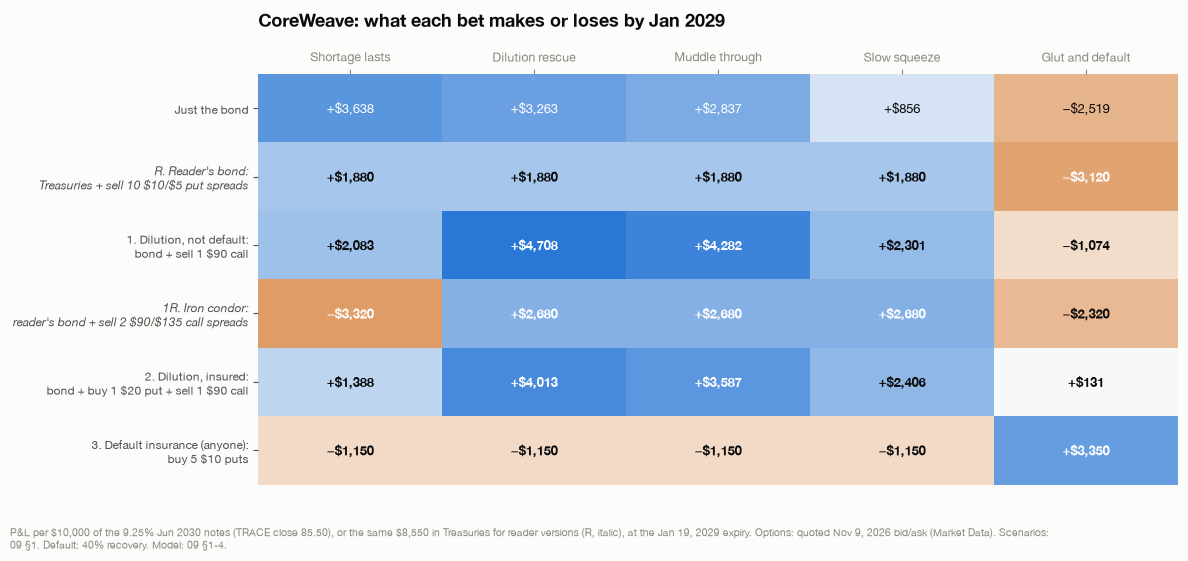

In [7]:
def trade_map(t, rows, title, fname, note):
    """Heatmap of P&L: trades down the side, scenarios across. Blue = gain, orange = loss. Reader versions (R) in italics."""
    d = pnl[t].loc[rows]
    lim = np.abs(d.values).max()
    cmap = LinearSegmentedColormap.from_list('pl', [EQUITY, '#fcfcfb', BOND])
    fig, ax = plt.subplots(figsize=(1.75 * d.shape[1] + 3.2, 0.62 * len(rows) + 1.6))
    ax.imshow(d.values, cmap=cmap, vmin=-lim, vmax=lim, aspect='auto')
    for (i, j), v in np.ndenumerate(d.values):
        ax.text(j, i, f"{'+' if v > 0 else '−'}${abs(v):,.0f}", ha='center', va='center', fontsize=9.5,
                color='white' if abs(v) > 0.55 * lim else INK, fontweight='bold' if rows[i] != BOND_ONLY else 'normal')
    ax.set_xticks(range(d.shape[1]), [c.replace(', ', ',\n').replace(' on ', '\non ') for c in d.columns], fontsize=9)
    ax.set_yticks(range(len(rows)), [r.replace(': ', ':\n', 1).replace(' + sell a', '\n+ sell a') for r in rows], fontsize=8.5)
    for lab, r in zip(ax.get_yticklabels(), rows):
        if 'R. ' in r.split(':')[0] + ' ': lab.set_fontstyle('italic')
    ax.xaxis.tick_top(); ax.grid(False)
    for sp in ax.spines.values(): sp.set_visible(False)
    ax.set_title(title, pad=34)
    source_note(fig, note)
    fig.tight_layout(rect=(0, 0.05, 1, 1))
    fig.savefig(CHARTS / fname, dpi=200, bbox_inches='tight')
    plt.show()

trade_map('CRWV', [BOND_ONLY, RB, T1, T1R, T2, T3], 'CoreWeave: what each bet makes or loses by Jan 2029', '09_coreweave_trades.png',
          f'P&L per $10,000 of the 9.25% Jun 2030 notes (TRACE close {PX[C]:.2f}), or the same ${CASH["CRWV"]:,.0f} in Treasuries for reader versions (R, italic), '
          f'at the Jan 19, 2029 expiry. Options: quoted {AS_OF:%b %-d, %Y} bid/ask (Market Data). Scenarios: 09 §1. Default: 40% recovery. Model: 09 §1-4.')

**What this shows** (`charts/09_coreweave_trades.png`; reader versions in italics):
- **Puts are the bear trade.** Five $10 puts cost $1,150 and pay ~$3,350 net in a default. They lose only what you paid, whatever happens.
  - They need CoreWeave below ~$7.70 in Jan 2029. The options market gives that ~26% odds, the same as 06 §8's ~26% for a ≥90% fall. So you're betting default is likelier, *and sooner*, than the market thinks.
- **Shorting the bond is the worse bear trade, so it's not in the chart.**
  - It pays less in a default (~$2,100), because you've been paying the bond's 9.25% coupon all along.
  - It costs ~$3,200–4,000 if CoreWeave muddles through or better.
  - **The same ~15% that makes the bond attractive to own makes it expensive to bet against.**
- **Reader versions vs. bond versions:**
  - The reader's bond earns about two-thirds of what the 144A bond does when CoreWeave survives (~$1,900 vs. ~$2,800–3,600).
  - It loses more in a default (~$3,100 vs. ~$2,500), because it never collected the bond's 9.25% coupons.
  - That's §2's ~5-point gap, in dollars.

In [8]:
import matplotlib.ticker as mticker
def payoffs(t, pairs, title, fname, note, xmax):
    """Small multiples: each reader trade's P&L against the stock price on Jan 19, 2029 (solid), its value with a year
    still to go (dashed), and the institution's bond version in each scenario (dots)."""
    S = np.linspace(0.5, xmax, 300)
    fig, axes = plt.subplots(1, len(pairs), figsize=(4.3 * len(pairs), 4.6), sharey=True)
    for ax, (reader, inst) in zip(axes, pairs):
        ax.axhline(0, color=AXIS, lw=1)
        ax.axvline(SPOT[t], color=AXIS, lw=1, ls=':')
        ax.text(SPOT[t], 0.01, f' today ${SPOT[t]:.0f}', transform=ax.get_xaxis_transform(), fontsize=8, color=MUTED, va='bottom')
        ax.plot(S, [mark(t, reader, s, T - 1) for s in S], color=EQUITY, lw=1.5, ls='--', label='With a year left (Jan 2028)')
        ax.plot(S, [mark(t, reader, s, 0) for s in S], color=EQUITY, lw=2.2, label='At expiry (Jan 2029)')
        if inst:
            sc = SCEN[t]
            ax.plot([sc[k]['stock'] for k in sc], pnl[t].loc[inst, list(sc)], 'o', ms=8, color=BOND, mec='white', mew=1.5, zorder=4,
                    label=f'{inst.split(":")[0]} (with the 144A bond), by scenario')
        head, legs_ = reader.split(': ', 1)
        ax.set_title(head + '\n' + legs_.replace(' + sell', '\n+ sell'), loc='left', fontsize=9.5)
        ax.set_xlabel(f'{"CoreWeave" if t == "CRWV" else "SpaceX"} stock price, Jan 19, 2029')
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'${v:,.0f}'))
        ax.legend(loc='best', fontsize=7.5, frameon=False)
    axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{'+' if v > 0 else '−' if v < 0 else ''}${abs(v):,.0f}"))
    axes[0].set_ylabel('Profit or loss')
    fig.suptitle(title, x=0.02, ha='left', fontsize=13, fontweight='bold')
    source_note(fig, note)
    fig.tight_layout(rect=(0, 0.06, 1, 0.94))
    fig.savefig(CHARTS / fname, dpi=200, bbox_inches='tight')
    plt.show()

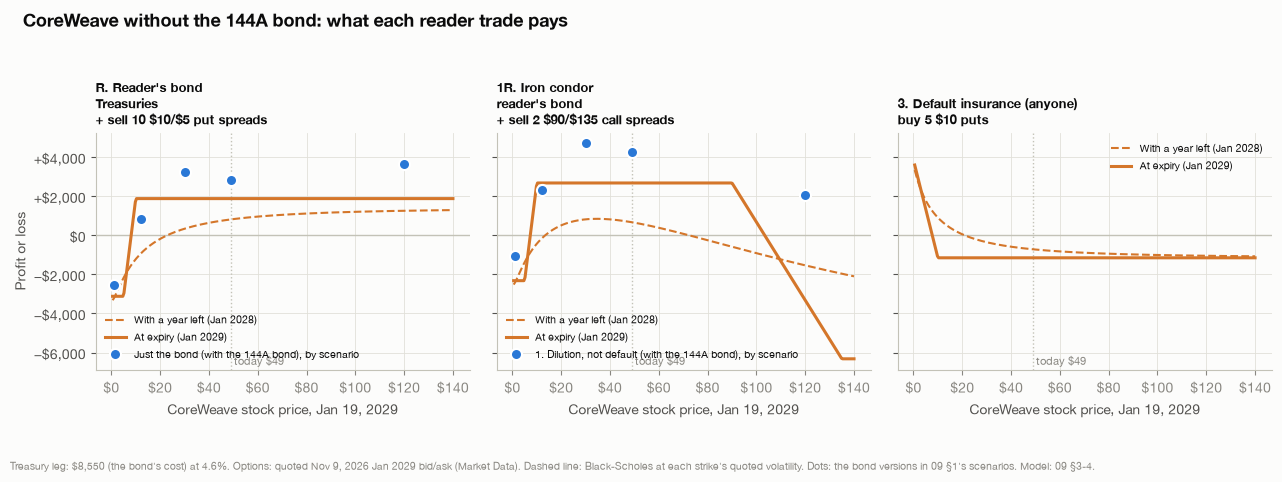

In [9]:
payoffs('CRWV', [(TR('CRWV', 'R.'), BOND_ONLY), (TR('CRWV', '1R.'), TR('CRWV', '1.')), (TR('CRWV', '3.'), None)],
        'CoreWeave without the 144A bond: what each reader trade pays', '09_coreweave_payoffs.png',
        f'Treasury leg: ${CASH["CRWV"]:,.0f} (the bond\'s cost) at {100 * TSY_Y:.1f}%. Options: quoted {AS_OF:%b %-d, %Y} Jan 2029 bid/ask (Market Data). '
        'Dashed line: Black-Scholes at each strike\'s quoted volatility. Dots: the bond versions in 09 §1\'s scenarios. Model: 09 §3-4.', 140)

**What this shows** (`charts/09_coreweave_payoffs.png`). The heatmap shows five stock prices. These payoff charts show every price, which is how an options trader reads a trade:
- **The solid line is the P&L at expiry. Its corners are the strikes.**
  - The reader's bond is flat above $10 and drops to its floor below $5, the shape of a bond.
  - The iron condor adds a cliff between $90 and $135: the "sell the upside" leg.
  - The puts are the mirror: a floor everywhere above $10, and a ramp below.
- **The blue dots are the institutional bond version in each scenario.** They sit above the reader lines when CoreWeave survives (the 144A bond's extra yield) and close to them in a default.
- **The dashed line is what you'd get if you closed the trade a year early,** with every option still priced at today's volatility.
  - The sold insurance is still worth a lot with a year left, so the reader's bond shows only ~+$800 at today's price, against ~+$1,880 at expiry.
  - **Writing insurance pays at the end; buying it pays early.** The puts' dashed line sits above their solid line, because a year early they still have value even if CoreWeave is above $10.

**Next:** the same tools on SpaceX, where the stock and the bonds disagree far more (06 §7).

## 5 · SpaceX: how do you bet "solvent but overvalued"?

**Why ask.** Put two findings together and you get a view the market doesn't price: **the stock is too high, and the bonds are fine.**
- Our SpaceX IPO post valued the company at ~$350B, against a ~$1.9T market value today.
- This project found SpaceX can almost certainly pay its bonds, because it can stop buying GPUs and Starlink funds itself (06 §4–5).

**The trades** (institutional versions use $10,000 of the 5.35% July 2031 notes; reader versions put the same ~$9,300 in Treasuries):
- **Trade 4: bond + buy a Jan 2029 $75 put + sell a $250 call.** The sold call pays for the put, so you get paid to put this on.
- **Trade 4R (readers): a "seagull".** Treasuries + buy a $75/$25 put spread + sell a $250/$295 call spread. The name comes from the payoff's shape: a wing down, a flat body, a wing up. Every loss is capped.
- **Trade 5: bond + buy a $100 put.** There's no sold call, so no cap if AI wins. The bond's ~7% does the paying instead.
- **Trade 5R (readers): Treasuries + buy a $100/$25 put spread.** The Treasury interest pays for most of the put spread.
- **Trade 6: bond + sell a $200 call.** This is trade 1's structure on SpaceX: they'll pay, and the stock goes nowhere.

In [10]:
T4, T4R, T5, T5R, T6 = (TR('SPCX', p) for p in ['4.', '4R.', '5.', '5R.', '6.'])
net4 = 100 * (quote('SPCX', 'call', 250, 'sell') - quote('SPCX', 'put', 75, 'buy'))
cost4r = 100 * (quote('SPCX', 'put', 75, 'buy') - quote('SPCX', 'put', 25, 'sell') - quote('SPCX', 'call', 250, 'sell') + quote('SPCX', 'call', 295, 'buy'))
put100 = quote('SPCX', 'put', 100, 'buy')
cost5r = 100 * (put100 - quote('SPCX', 'put', 25, 'sell'))
call200 = quote('SPCX', 'call', 200, 'sell')
ann6 = (1 + sx.loc[T6, 'Muddle through'] / CASH['SPCX']) ** (1 / T) - 1
be6 = 200 + (bond_leg(S31, SCEN['SPCX']['AI wins']) + 100 * call200) / 100
print(f"$350B is ${SPX_350B:.2f} a share, {1 - SPX_350B / SPOT['SPCX']:.0%} below today; options-market odds of ending below it: {odds('SPCX', SPX_350B):.0%}.")
print(f'Trade 4 collects ${net4:,.0f} up front. 4R (the seagull) costs ${cost4r:,.0f}, against ${cash_leg(CASH["SPCX"]):,.0f} of Treasury interest. '
      f'Odds SpaceX ends above $250: {odds("SPCX", 250, below=False):.0%}.')
print(f'Trade 5: the $100 put costs ${100 * put100:,.0f}; the bond earns ${sx.loc[BOND_ONLY, "Muddle through"]:,.0f} if nothing changes. '
      f'5R: the $100/$25 put spread costs ${cost5r:,.0f} and pays up to $7,500. Odds SpaceX ends below $100: {odds("SPCX", 100):.0%}.')
print(f'Trade 6: the $200 call pays ${100 * call200:,.0f}. If nothing changes it earns {ann6:.1%} a year vs. the bond\'s {NOW_Y[S31]:.1f}%. '
      f'It loses money above ~${be6:.0f} (odds {odds("SPCX", be6, below=False):.0%}).')
sx.loc[[BOND_ONLY, T4, T4R, T5, T5R, T6]].round(0)

$350B is $25.77 a share, 82% below today; options-market odds of ending below it: 6%.
Trade 4 collects $1,135 up front. 4R (the seagull) costs $460, against $955 of Treasury interest. Odds SpaceX ends above $250: 17%.
Trade 5: the $100 put costs $1,760; the bond earns $1,487 if nothing changes. 5R: the $100/$25 put spread costs $1,680 and pays up to $7,500. Odds SpaceX ends below $100: 44%.
Trade 6: the $200 call pays $3,080. If nothing changes it earns 20.0% a year vs. the bond's 7.2%. It loses money above ~$248 (odds 17%).


,AI wins,AI wins on borrowed money,Muddle through,"Worth $350B, solvent",Primed,Distress
Just the bond,1753.0,1104.0,1487.0,1422.0,900.0,-4099.0
4. Solvent but overvalued: bond + buy 1 $75 put + sell 1 $250 call,-2112.0,2239.0,2622.0,7480.0,2035.0,4036.0
4R. Seagull: Treasuries + buy a $75/$25 put spread + sell a $250/$295 call spread,-4005.0,495.0,495.0,5418.0,495.0,5495.0
5. Let the bond buy your put: bond + buy 1 $100 put,-7.0,-656.0,-273.0,7085.0,140.0,3641.0
5R. Let Treasuries buy your put spread: Treasuries + buy a $100/$25 put spread,-725.0,-725.0,-725.0,6698.0,275.0,6775.0
"6. Bonds paid, stock stalls: bond + sell 1 $200 call",-5167.0,-816.0,4567.0,4502.0,3980.0,-1019.0


**What this shows** (the table above; charted in §6):
- **Trade 4 gets paid to set up.** Selling the $250 call brings in ~$1,100 more than the $75 put costs. Options price SpaceX at ~53–61% yearly swings, so both legs are expensive, and you're selling the more expensive one.
  - **If our IPO post was right, it makes ~+$7,500.** The bond is repaid and the put pays ~$4,900.
  - The options market gives a fall that large (~82%) only ~6% odds. That's what conviction is worth: you're paid well because few people share the view.
  - It loses ~$2,100 if AI wins, because the sold call caps your upside.
- **Trade 4R does the same job with capped risk.**
  - The seagull's options cost ~$460, about half the ~$955 the Treasuries earn. So it makes ~$500 if nothing changes, and ~$5,400–5,500 at $350B or in distress.
  - It loses ~$4,000 if AI wins, more than trade 4. Without the bond's coupons, there's less cushion.
- **Trades 5 and 5R are the cleanest bets in the notebook: neither loses more than ~$725, and both make ~$6,700–7,100 at $350B.**
  - The $100 put costs $1,760. If nothing changes, the bond earns ~$1,490 by Jan 2029, so trade 5 loses ~$270.
  - **In distress the reader version wins (~$6,800 vs. ~$3,600).** Treasuries don't default, and the 144A bond does.
  - The catch: they only pay big on a large fall. The options market puts SpaceX below $100 in Jan 2029 at ~44%, and below ~$26 at ~6%.
- **Trade 6 turns a 7.2% bond into ~20% a year if SpaceX stays below $200.**
  - It makes ~$4,000–4,600 if SpaceX is primed, worth $350B, or unchanged. It loses ~$1,000 in distress, vs. ~$4,100 for the bond alone.
  - It loses money above ~$248 (~17% odds), and its losses are unlimited above that. At $300 it's ~−$5,200.
  - **There's no good reader version.** The CoreWeave equivalent (1R) works because CoreWeave's sold put spreads pay real premium. SpaceX's pay almost nothing (§2), so an iron condor on SpaceX is mostly the call spread's risk.

**Next:** what if you think AI wins?

## 6 · SpaceX: how do you bet on AI winning, and what does each trade look like?

**Why ask.** The bull case is simple: buy calls. But calls expire worthless most of the time. A **convertible bond** solves that by bundling a bond with a call, so you keep the bond if the call expires worthless.

**How a real convertible works.** CoreWeave sold one in September (08): $4.2B of 2.875% notes due 2033.
- Each $1,000 note pays interest like a bond. Instead of taking $1,000 back, the holder can swap it for ~10.2 shares, a "conversion price" of $97.85, set 22.5% above the stock that day.
- **So a convertible is two things glued together: a bond, plus a call on ~10 shares per $1,000 with a $97.85 strike.**
- The holder pays for the call with a lower coupon. CoreWeave's straight 2032 notes pay 9.625%, the convertible 2.875%. That's ~6.75 points a year, every year, handed over for the calls.
- CoreWeave likes this because it borrows at 2.875%. If the stock soars, it repays in shares (dilution) instead of cash. That's why 08 §5 counts the convertibles alongside the straight bonds.

**How we built ours.** SpaceX hasn't issued a convertible, but you can glue the two pieces together yourself:
- **The bond piece:** $10,000 of the 5.35% 2031 notes, ~$9,274 at Nov 10's TRACE price.
- **The call piece:** one Jan 2029 $150 call, on 100 shares. That's 10 shares per $1,000 of bonds, the same ratio as CoreWeave's, with a "conversion price" of $150, ~6% above today's ~$142.
- **The difference from the real thing:** you pay for the call up front (~$4,690, ~51% of the bond's cost) instead of through a lower coupon. In return, the two pieces stay separate: you can sell either one.
- Our call also expires in Jan 2029, 2.5 years before the bond matures. A real convertible's call lasts as long as the bond does.

**The trades:**
- **Trade 7: buy $10,000 of the 2031 notes and one Jan 2029 $150 call.**
- **Trade 7R (readers): Treasuries + a $150/$295 call spread.** Same glue, different pieces:
  - Treasuries replace the bond.
  - Selling a $295 call (the highest listed strike) refunds ~$1,615 of the $150 call's cost, in exchange for capping your upside at $295.

We also tried a "Musk maximalist" trade: buy the call and short the 2056 bonds, which would be the most exposed if SpaceX borrows heavily. It's priced below to show why we dropped it.

In [11]:
T7, T7R = TR('SPCX', '7.'), TR('SPCX', '7R.')
call150 = quote('SPCX', 'call', 150, 'buy')
cost7r = 100 * (call150 - quote('SPCX', 'call', 295, 'sell'))
mm = sx.loc[TR('SPCX', 'Dropped: Musk')]
call_only = opt_leg('SPCX', 'call', 150, 1, SCEN['SPCX']['AI wins on borrowed money'])
print(f'The $150 call costs ${100 * call150:,.0f} and pays off above ${150 + call150:.0f} (odds {odds("SPCX", 150 + call150, below=False):.0%}). '
      f'7R swaps it for a $150/$295 call spread costing ${cost7r:,.0f}, and the bond for Treasuries.')
print(f'7R vs. 7: ' + ', '.join(f'{k} {sx.loc[T7R, k] - sx.loc[T7, k]:+,.0f}' for k in sx.columns))
print(f"Dropped 'Musk maximalist' (the call + short the 2056 bonds): in its own scenario, AI wins on borrowed money, the short 2056s make "
      f"${mm['AI wins on borrowed money'] - call_only:,.0f}, because you pay their 6.65% coupon the whole time. The call alone makes ${call_only:,.0f} there.")
sx.loc[[BOND_ONLY, T7, T7R, TR('SPCX', 'Dropped: Musk')]].round(0)

The $150 call costs $4,690 and pays off above $197 (odds 28%). 7R swaps it for a $150/$295 call spread costing $3,075, and the bond for Treasuries.
7R vs. 7: AI wins +317, AI wins on borrowed money +1,466, Muddle through +1,083, Worth $350B, solvent +1,148, Primed +1,670, Distress +6,669
Dropped 'Musk maximalist' (the call + short the 2056 bonds): in its own scenario, AI wins on borrowed money, the short 2056s make $344, because you pay their 6.65% coupon the whole time. The call alone makes $5,310 there.


,AI wins,AI wins on borrowed money,Muddle through,"Worth $350B, solvent",Primed,Distress
Just the bond,1753.0,1104.0,1487.0,1422.0,900.0,-4099.0
7. Homemade convertible: bond + buy 1 $150 call,12063.0,6414.0,-3203.0,-3268.0,-3790.0,-8789.0
7R. Treasury convertible: Treasuries + buy a $150/$295 call spread,12380.0,7880.0,-2120.0,-2120.0,-2120.0,-2120.0
"Dropped: Musk maximalist, buy 1 $150 call + short the 2056 bonds",6717.0,5654.0,-6600.0,-6136.0,-3815.0,-2092.0


In [12]:
# How our homemade convertible compares with a real one: CoreWeave's 2.875% 2033 convertible (08's inputs, from its 8-K)
neo = pd.read_csv('data/neocloud_inputs.csv').set_index('item')
conv_px = neo.loc['crwv_conv_2033_price', 'value']               # conversion price, $/share
CONV_CPN, STRAIGHT = 2.875, 'CRWV_9.625_2032'                   # coupon from the 8-K (note text in neocloud_inputs.csv); nearest straight bond
calls_hm = 100 * call150 / CASH['SPCX']                          # homemade: call cost as a share of the bond's cost
print(f"A real convertible: each $1,000 of CoreWeave's 2033 notes converts into {1000 / conv_px:.2f} shares (conversion price ${conv_px:.2f}, "
      f"22.5% above the stock at issue). It pays {CONV_CPN}% where CoreWeave's straight {bonds.loc[STRAIGHT, 'coupon']}% 2032 notes pay full price, "
      f"so holders give up ~{bonds.loc[STRAIGHT, 'coupon'] - CONV_CPN:.2f} points of coupon a year to own the calls.")
print(f"Our homemade one: per $1,000 of SpaceX 2031 notes, a call on 10 shares at $150 ({150 / SPOT['SPCX'] - 1:.0%} above today). "
      f"The call costs {calls_hm:.0%} of the bond's price up front, about {calls_hm / T:.0%} a year of the 2.2 years it runs.")

A real convertible: each $1,000 of CoreWeave's 2033 notes converts into 10.22 shares (conversion price $97.85, 22.5% above the stock at issue). It pays 2.875% where CoreWeave's straight 9.625% 2032 notes pay full price, so holders give up ~6.75 points of coupon a year to own the calls.
Our homemade one: per $1,000 of SpaceX 2031 notes, a call on 10 shares at $150 (6% above today). The call costs 51% of the bond's price up front, about 23% a year of the 2.2 years it runs.


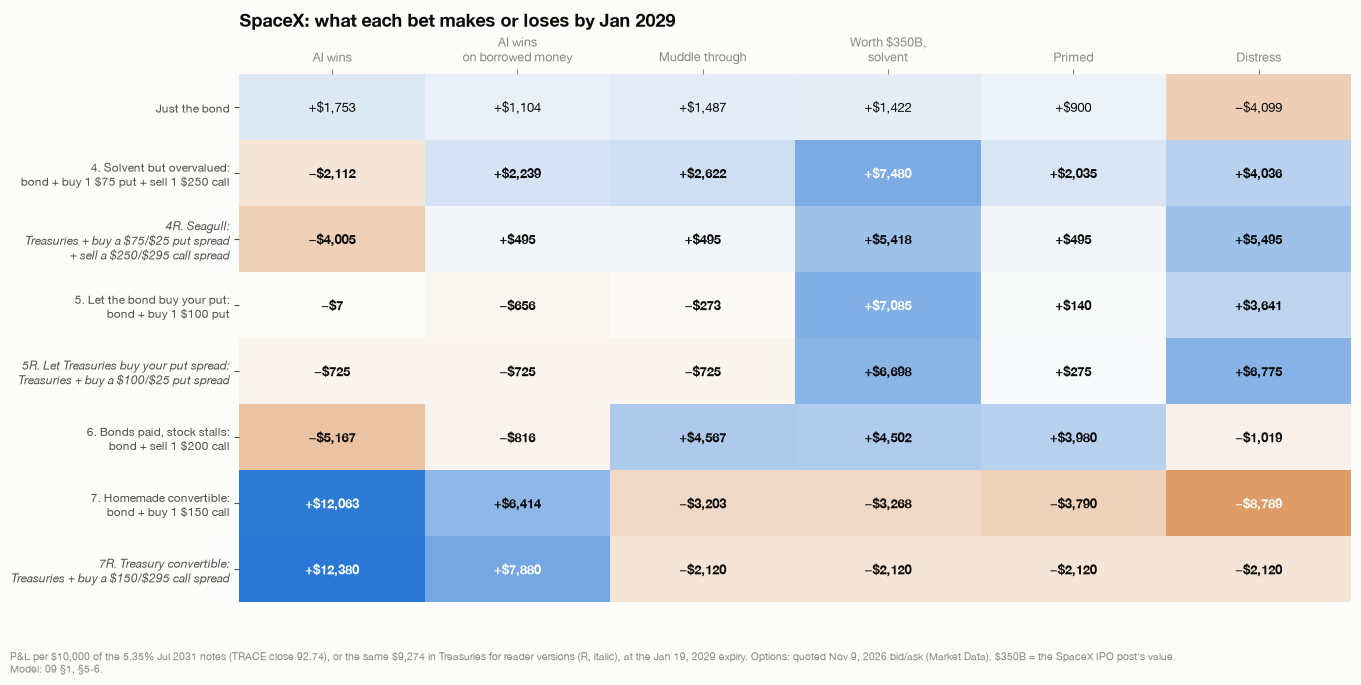

In [13]:
trade_map('SPCX', [BOND_ONLY, T4, T4R, T5, T5R, T6, T7, T7R], 'SpaceX: what each bet makes or loses by Jan 2029', '09_spacex_trades.png',
          f'P&L per $10,000 of the 5.35% Jul 2031 notes (TRACE close {PX[S31]:.2f}), or the same ${CASH["SPCX"]:,.0f} in Treasuries for reader versions (R, italic), '
          f'at the Jan 19, 2029 expiry. Options: quoted {AS_OF:%b %-d, %Y} bid/ask (Market Data). $350B = the SpaceX IPO post\'s value. Model: 09 §1, §5-6.')

**What this shows** (`charts/09_spacex_trades.png`; reader versions in italics):
- **Trade 7 is the biggest win in the notebook, ~+$12,100 if AI wins, and the biggest loss, ~−$8,800 in distress.**
  - The call costs $4,690 and pays off above ~$197 (~28% odds).
  - In distress the bond adds a ~$4,100 loss. **A convertible's bond is only as safe as the company.**
- **Trade 7R beats it in every scenario:** by ~$300 if AI wins, by ~$1,100–1,700 in the middle, and by ~$6,700 in distress.
  - The call spread is cheaper than the call, and Treasuries can't default.
  - Over two years, SpaceX's ~2.6 points of extra yield doesn't pay for its default risk in this trade. That's §2's finding again: a reader loses nothing by not being able to buy the bond.
- **Across the SpaceX grid, the reader versions do better than the bond versions in distress every time,** and give up up to ~$2,100 elsewhere (the convertible's reader version gives up nothing).
- **Shorting a bond to bet on priming doesn't pay.** The short 2056s make ~$340 even in their own scenario, because you pay their 6.65% coupon the whole way. The 2056s would have to fall ~18 points just to cover that (~14.6 points of coupons plus the borrow fee). It's the same lesson as §4: the yield that makes a bond attractive to own makes it expensive to bet against.

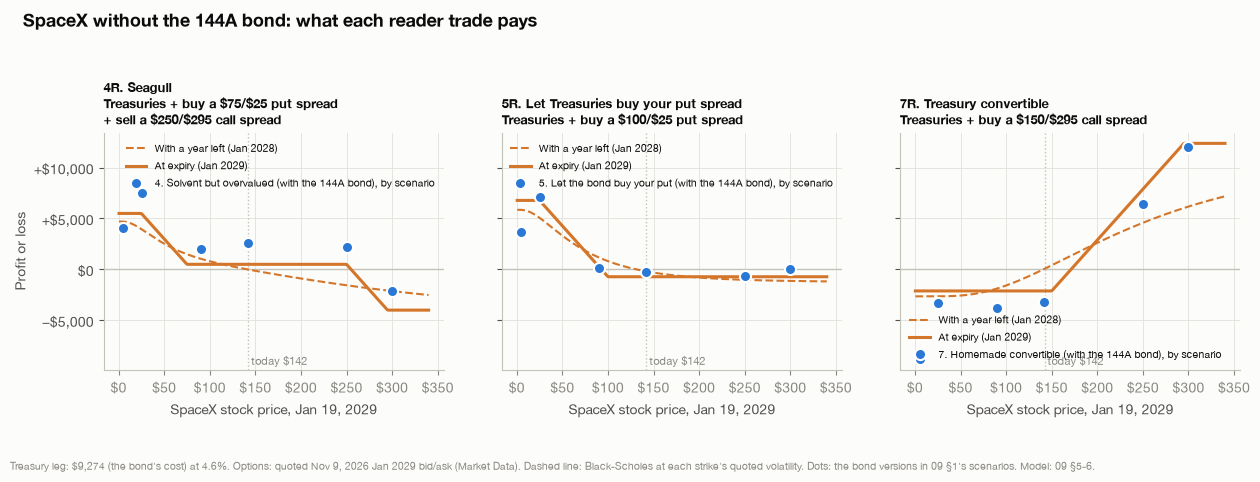

In [14]:
payoffs('SPCX', [(TR('SPCX', '4R.'), TR('SPCX', '4.')), (TR('SPCX', '5R.'), TR('SPCX', '5.')), (TR('SPCX', '7R.'), TR('SPCX', '7.'))],
        'SpaceX without the 144A bond: what each reader trade pays', '09_spacex_payoffs.png',
        f'Treasury leg: ${CASH["SPCX"]:,.0f} (the bond\'s cost) at {100 * TSY_Y:.1f}%. Options: quoted {AS_OF:%b %-d, %Y} Jan 2029 bid/ask (Market Data). '
        'Dashed line: Black-Scholes at each strike\'s quoted volatility. Dots: the bond versions in 09 §1\'s scenarios. Model: 09 §5-6.', 340)

**What this shows** (`charts/09_spacex_payoffs.png`):
- **The seagull (4R)** has a flat body from $75 to $250, where you keep ~$500 of Treasury interest. It rises to ~$5,500 below $25 and falls to ~−$4,000 above $295.
  - The blue dots (trade 4, with the bond) sit above the line in the middle, because of the bond's coupons. They sit below it in distress.
- **The put spread (5R)** is the "insurance" shape: a small flat loss above $100, and a ramp to ~$6,800 at $25 and below. The dots for trade 5 track it closely, except in distress.
- **The Treasury convertible (7R)** is the mirror: a flat ~−$2,120 below $150, and a ramp to ~$12,400 at $295 and above.
- **The dashed lines (a year early) are smoother than the solid ones.**
  - Near the strikes, bought options keep value before expiry. So 7R's dashed line sits above its floor between ~$100 and $150.
  - Far from the strikes the dashed line sits a little lower, because a year early you've collected a year less Treasury interest, and the payoff hasn't locked in.

**Next:** what does a reader need to put these on?

## 7 · How do you build each trade without the 144A bond?

**Why ask.** §3–6 gave each institutional trade a reader version. This section shows the recipe: which piece replaces which, what each swap costs, and the exact orders to place.

**The translation, leg by leg:**

| The institution holds… | The reader uses… | Why it works | What it costs you |
|---|---|---|---|
| **The bond, if the company survives** (coupons + price recovery) | **Treasuries** with the same cash | Both pay a fixed return if nothing goes wrong. | The credit spread: ~10 points a year on CoreWeave, ~2.6 on SpaceX. |
| **The bond's default risk** (a ~$4,550 price loss if CoreWeave defaults) | **Sold deep put spreads** ($10/$5 on CoreWeave) | A sold put is insurance against the stock collapsing. The bought lower put caps the loss, like a recovery rate. The premium is your "extra coupon". | Earns less than the bond's spread (§2). SpaceX's version pays almost nothing, so for SpaceX, skip it. |
| **A sold call** (trades 1, 4, 6) | **A sold call spread** (sell the call, buy a higher one) | Same income when the stock stays below the strike. | Less premium, because you spend some on the higher call. Your loss is capped instead of unlimited. |
| **A bought put** (trades 4, 5) | **A bought put spread** (buy the put, sell a lower one) | Pays the same down to the lower strike. | Gives up the payoff below ~$25. On SpaceX that's ~6% odds, and it's where the bond version would be in default anyway. |
| **A bought call** (trade 7) | **A bought call spread** | Pays the same up to the higher strike. | Caps your upside at $295 in exchange for ~$1,615 back. |

**Method.** The table below lists the orders for each reader trade: the leg, the option symbol (OCC format: ticker, expiry YYMMDD, P/C, strike × 1,000), the quantity, and the closing price you'd have paid or received. It then gives each trade's most it can make and lose at expiry, and its break-even stock prices.

In [15]:
def tickets(t, name):
    """The orders to place for a reader trade: one row per leg, at the quoted closing bid/ask."""
    rows = [] if name in CASH_FREE else [{'leg': f'Buy Treasuries maturing ~Jan 2029', 'symbol': '—', 'qty': f'${CASH[t]:,.0f}', 'price': '—', 'cash': -CASH[t]}]
    for k, K, n in READER[t][name]:
        q = OPT[t].query('side == @k and strike == @K').iloc[0]
        px = q.ask if n > 0 else q.bid
        rows.append({'leg': f'{"Buy" if n > 0 else "Sell"} to open Jan 19 2029 ${K} {k}', 'symbol': q.optionSymbol, 'qty': abs(n),
                     'price': f'${px:.2f}', 'cash': -100 * n * px})
    return pd.DataFrame(rows)

def at_expiry(t, name, S):
    """A reader trade's P&L at expiry for an array of stock prices (vectorised mark(..., tau=0))."""
    v = np.full_like(S, 0.0 if name in CASH_FREE else cash_leg(CASH[t]))
    for k, K, n in READER[t][name]:
        pay = np.maximum(S - K, 0) if k == 'call' else np.maximum(K - S, 0)
        v += 100 * n * (pay - quote(t, k, K, 'buy' if n > 0 else 'sell'))
    return v

assert abs(at_expiry('CRWV', TR('CRWV', '1R.'), np.array([30.0]))[0] - mark('CRWV', TR('CRWV', '1R.'), 30.0, 0)) < 1e-6

def profile(t, name):
    """Most it can make and lose at expiry, and the stock prices where it breaks even."""
    S = np.arange(0.05, max(3 * SPOT[t], 1.5 * max(K for _, K, _ in READER[t][name])), 0.05)   # past the top strike
    v = at_expiry(t, name, S)
    cross = S[1:][np.sign(v[1:]) != np.sign(v[:-1])]
    return {'max gain': v.max(), 'max loss': v.min(), 'break-even(s)': ', '.join(dict.fromkeys(f'${c:.0f}' for c in cross)) or 'none'}

prof = pd.DataFrame({(t, n.split(':')[0]): profile(t, n) for t in READER for n in READER[t]}).T
prof['options cash at entry'] = [-100 * sum(n * quote(t, k, K, 'buy' if n > 0 else 'sell') for k, K, n in READER[t][name]) for t in READER for name in READER[t]]
prof.rename_axis(['ticker', 'trade']).to_csv('data/trade_profiles.csv')   # handoff to research.ipynb
for t in READER:
    for n in READER[t]:
        tk = tickets(t, n)
        print(f'\n{n}\n  net options cash at entry: ${tk[tk.symbol != "—"].cash.sum():+,.0f}; '
              f'Treasury interest by Jan 2029: ${0 if n in CASH_FREE else cash_leg(CASH[t]):,.0f}')
        print(tk.to_string(index=False, formatters={'cash': lambda v: f'{v:+,.0f}'}))
prof.style.format({'max gain': '${:,.0f}', 'max loss': '${:,.0f}', 'options cash at entry': '${:+,.0f}'})


R. Reader's bond: Treasuries + sell 10 $10/$5 put spreads
  net options cash at entry: $+1,000; Treasury interest by Jan 2029: $880
                              leg              symbol    qty price   cash
Buy Treasuries maturing ~Jan 2029                   — $8,550     — -8,550
 Sell to open Jan 19 2029 $10 put CRWV290119P00010000     10 $2.00 +2,000
   Buy to open Jan 19 2029 $5 put CRWV290119P00005000     10 $1.00 -1,000

1R. Iron condor: reader's bond + sell 2 $90/$135 call spreads
  net options cash at entry: $+1,800; Treasury interest by Jan 2029: $880
                              leg              symbol    qty  price   cash
Buy Treasuries maturing ~Jan 2029                   — $8,550      — -8,550
 Sell to open Jan 19 2029 $10 put CRWV290119P00010000     10  $2.00 +2,000
   Buy to open Jan 19 2029 $5 put CRWV290119P00005000     10  $1.00 -1,000
Sell to open Jan 19 2029 $90 call CRWV290119C00090000      2 $14.45 +2,890
Buy to open Jan 19 2029 $135 call CRWV290119C00135000      

**What this shows** (the order tickets and the table above):
- **Every reader trade is 2–5 orders, all on the Jan 19, 2029 expiry, plus a Treasury purchase.** Most brokers let you enter the option legs as one multi-leg order at a net price (a "credit" or "debit"). That's safer than placing legs one at a time and having the stock move in between.
- **The cash moves are small next to the Treasury leg.**
  - The iron condor *collects* ~$1,800 up front.
  - The seagull costs ~$460, about half the ~$955 the Treasuries earn by expiry.
  - The Treasury convertible costs ~$3,075.
- **Every loss is capped, and you know the cap before you start:**
  - Iron condor: ~$6,300, if CoreWeave ends above $135.
  - Seagull: ~$4,000, if SpaceX ends above $295.
  - Put spread: ~$725.
  - Treasury convertible: ~$2,120.
- **Break-evens tell you what has to happen:**
  - The iron condor needs CoreWeave between ~$7 and ~$103.
  - The put spread needs SpaceX below ~$93.
  - The convertible needs SpaceX above ~$171.
- **Prices move.** These are the Nov 9 closing quotes. Use limit orders at or near the mid, and re-price on the day.

**Next:** what the legs look like added together.

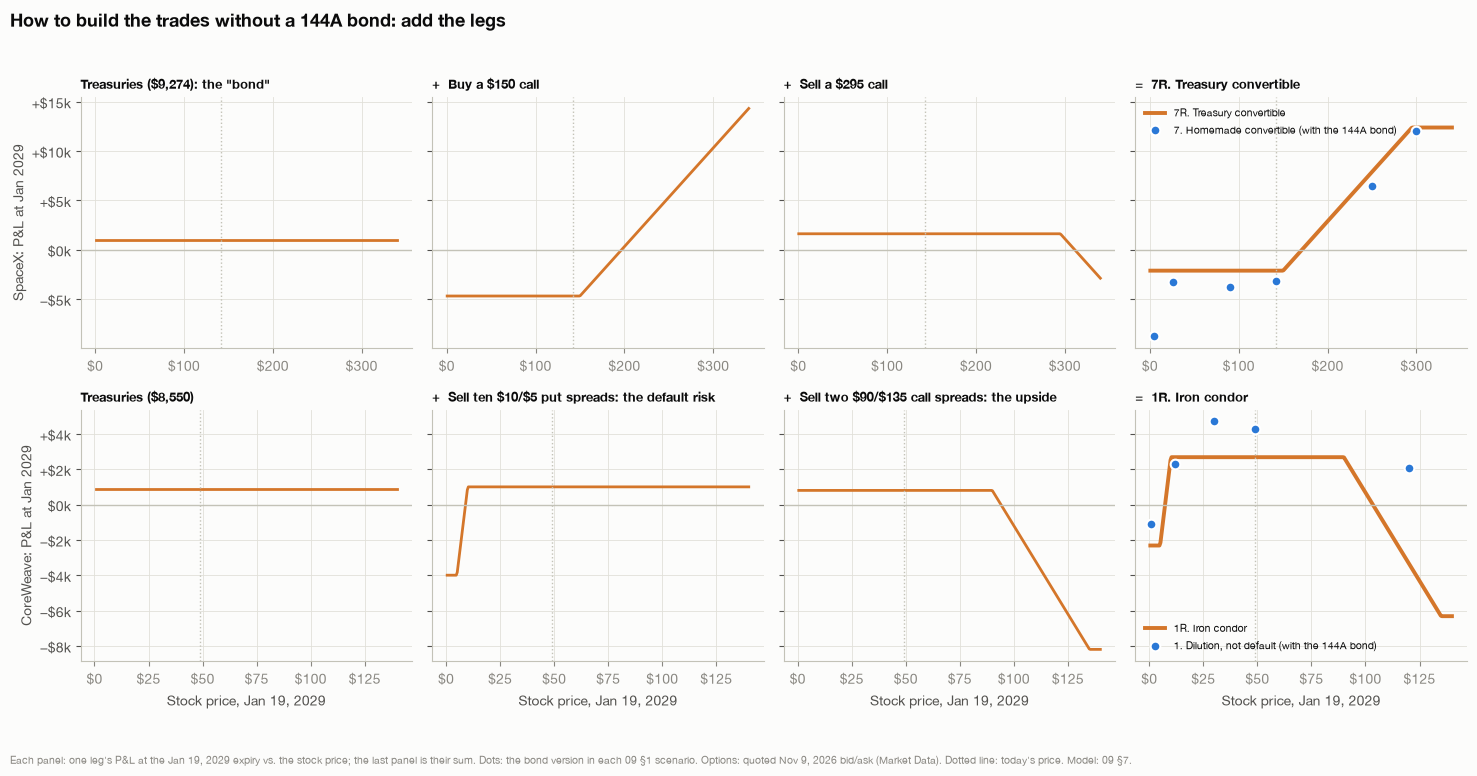

In [16]:
def blocks(ax_row, t, parts, inst, label_total):
    """One row of the building-blocks chart: each leg's P&L at expiry vs. the stock price, then their sum (bold)."""
    S = np.linspace(0.5, parts[0][2], 300)
    total = np.zeros_like(S)
    for i, (ax, (title, legs, _)) in enumerate(zip(ax_row, parts)):
        v = np.array([(cash_leg(CASH[t]) if legs == 'tsy' else 0) + (0 if legs == 'tsy' else sum(opt_leg(t, k, K, n, {'stock': s}) for k, K, n in legs)) for s in S])
        total += v
        ax.plot(S, v, color=EQUITY, lw=2)
        ax.set_title(('' if i == 0 else '+  ') + title, loc='left', fontsize=9.5)
    ax = ax_row[len(parts)]
    ax.plot(S, total, color=EQUITY, lw=2.8, label=label_total)
    sc = SCEN[t]
    ax.plot([sc[k]['stock'] for k in sc], pnl[t].loc[inst, list(sc)], 'o', ms=7, color=BOND, mec='white', mew=1.5, zorder=4,
            label=f'{inst.split(":")[0]} (with the 144A bond)')
    ax.set_title('=  ' + label_total, loc='left', fontsize=9.5, fontweight='bold')
    ax.legend(loc='best', fontsize=7.5, frameon=False)
    for ax in ax_row:
        ax.axhline(0, color=AXIS, lw=1)
        ax.axvline(SPOT[t], color=AXIS, lw=1, ls=':')
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'${v:,.0f}'))
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{'+' if v > 0 else '−' if v < 0 else ''}${abs(v) / 1000:,.0f}k"))

fig, axes = plt.subplots(2, 4, figsize=(15, 7.6), sharey='row')
blocks(axes[0], 'SPCX', [(f'Treasuries (${CASH["SPCX"]:,.0f}): the "bond"', 'tsy', 340), ('Buy a $150 call', [('call', 150, 1)], 340),
                         ('Sell a $295 call', [('call', 295, -1)], 340)], TR('SPCX', '7.'), '7R. Treasury convertible')
blocks(axes[1], 'CRWV', [(f'Treasuries (${CASH["CRWV"]:,.0f})', 'tsy', 140), ('Sell ten $10/$5 put spreads: the default risk', [('put', 10, -10), ('put', 5, 10)], 140),
                         ('Sell two $90/$135 call spreads: the upside', [('call', 90, -2), ('call', 135, 2)], 140)], TR('CRWV', '1.'), '1R. Iron condor')
axes[0, 0].set_ylabel('SpaceX: P&L at Jan 2029'); axes[1, 0].set_ylabel('CoreWeave: P&L at Jan 2029')
for ax in axes[1]: ax.set_xlabel('Stock price, Jan 19, 2029')
fig.suptitle('How to build the trades without a 144A bond: add the legs', x=0.01, ha='left', fontsize=13, fontweight='bold')
source_note(fig, f'Each panel: one leg\'s P&L at the Jan 19, 2029 expiry vs. the stock price; the last panel is their sum. Dots: the bond version in each 09 §1 scenario. '
                 f'Options: quoted {AS_OF:%b %-d, %Y} bid/ask (Market Data). Dotted line: today\'s price. Model: 09 §7.')
fig.tight_layout(rect=(0, 0.04, 1, 0.96))
fig.savefig(CHARTS / '09_how_to_build_it.png', dpi=200, bbox_inches='tight')
plt.show()

**What this shows** (`charts/09_how_to_build_it.png`):
- **Top row, the Treasury convertible:** a flat Treasury line, plus a bought call (the hockey stick up), plus a sold higher call (the hockey stick down). The sum is a floor at ~−$2,120 and a ramp from $150 that levels off at $295.
  - The blue dots (trade 7, with the 144A bond) sit a little below the line when SpaceX survives. The bond's extra coupon doesn't cover the extra cost of the uncapped call.
  - They sit far below it in distress.
- **Bottom row, the iron condor:**
  - Treasuries are the flat line.
  - The sold $10/$5 put spreads add a cliff near zero: the "default" part of the bond.
  - The sold $90/$135 call spreads add a cliff above $90: "selling the upside".
  - The sum is a plateau between $10 and $90, the range the trade bets on.
  - The blue dots (trade 1, with the bond) sit above the plateau (about level in the slow squeeze), because the 144A bond pays ~5 more points a year than the build can. That's the price of not being an institution.
- **The point for the post:** every trade here is Lego. A bond is Treasuries plus sold insurance; a convertible is a bond plus a call. Once you see the pieces, you can rebuild any of them from parts a reader can buy.

**Next:** which approvals a reader needs.

## 8 · What does a reader need to put these on?

| Leg | Can a retail investor do it? |
|---|---|
| **Buy CoreWeave or SpaceX bonds** | **Usually not.** Every CoreWeave and SpaceX bond here is a 144A issue (`bonds.csv`): sold only to "qualified institutional buyers" (roughly, institutions with $100M+ invested). Non-US investors may reach the Reg S versions. |
| **Short a bond** | **No.** Institutions borrow bonds through prime brokers, and borrow fees on 144A junk bonds can be high. |
| **Buy Treasuries** | Yes, at any broker or TreasuryDirect. |
| **Buy puts or calls** | Yes, with basic options approval. |
| **Spreads (put spreads, call spreads, iron condors, seagulls)** | Yes, usually at the "spreads" approval level. Because every sold option is paired with a bought one, the loss is capped and the broker holds the maximum loss as collateral. Treasuries can often serve as that collateral in a margin account. |
| **Sell calls without owning the stock ("naked")** | Only at the highest approval level, with margin. The loss is unlimited. This is why every reader version uses call *spreads*. |

**So the post should pair each institutional trade with its reader version:**
- R and 1R for trade 1.
- 4R for trade 4.
- 5R for trade 5.
- 7R for trade 7.

Trades 3 (puts) and 6 need no pairing: trade 3 works as is for anyone, and trade 6 has no good reader version (§5). §7 has the order tickets.

**Liquidity:** see the quote table in §1 (open interest per option, Nov 9). The SpaceX $25 and $295 options are very liquid (21,000+ and 18,000+ contracts). The CoreWeave $90 call (452) is the thinnest leg; the SpaceX $60 put in §9's build has only 130. Use limit orders at or near the mid.

## 9 · The post's trades: what does each one pay, and what yield is that?

**Why ask.** The post picks seven of the trades above (some in a slightly different form) and shows each with its own payoff chart. Since the post compares them with bonds, each one also needs a **yield**: the yearly return on the cash you put up, the same way a bond's yield is a yearly return on its price.

**Method.**
- Same pricing as §1: quoted closes, buy at the ask, sell at the bid, P&L at the Jan 19, 2029 expiry, per $10,000 of bond face (or the same cash in Treasuries).
- **Cash put up** = the bond's price (or the Treasuries), plus the options if they cost money. Option credits aren't subtracted (the broker holds them as collateral), and margin for a naked sold call isn't added, so trades 1 and 5 look a little better than they would on a margin statement.
- **Yearly return** = (1 + P&L ÷ cash put up)^(1 ÷ years to expiry) − 1. Comparable to a bond yield held to Jan 2029, not to maturity.
- **The build-your-own-bond trades** use the post's strikes ($20/$10 for CoreWeave, $60/$30 for SpaceX), sized as in §2: the most they can lose ≈ what the bond loses in a default.
- **Payoff charts:** the solid line is the P&L at expiry if the bond is repaid (priced at today's yield). For bond trades a dashed line shows a default at low stock prices. Dots are §1's scenarios, labelled with their yearly return.


In [17]:
# The post's trades, in the post's order. bond = None means the reader version: the same cash in Treasuries.
def build_n(t, bid, hi, lo):
    """How many hi/lo put spreads to sell so the most they can lose ≈ what the bond loses in a default (§2's sizing)."""
    credit = quote(t, 'put', hi, 'sell') - quote(t, 'put', lo, 'buy')
    return round((FACE * PX[bid] / 100 - FACE * bonds.loc[bid, 'assumed_recovery']) / (100 * (hi - lo - credit)))

NB_CW, NB_SX = build_n('CRWV', C, 20, 10), build_n('SPCX', S31, 60, 30)
POST = {   # key: (title, ticker, [(label, bond or None, legs)], x-axis max)
 'build': None,   # two panels, drawn below
 'trade1': ('Trade 1: Dilution, not default', 'CRWV',
            [('2030 notes + buy a $20 put + sell a $90 call', C, [('put', 20, 1), ('call', 90, -1)])], 160),
 'trade2': ('Trade 2: the iron condor', 'CRWV',
            [('Treasuries + sell ten $10/$5 put spreads + sell two $90/$135 call spreads', None,
              [('put', 10, -10), ('put', 5, 10), ('call', 90, -2), ('call', 135, 2)])], 160),
 'trade3': ('Trade 3: the SpaceX seagull', 'SPCX',
            [('Treasuries + buy a $75/$25 put spread + sell a $250/$295 call spread', None,
              [('put', 75, 1), ('put', 25, -1), ('call', 250, -1), ('call', 295, 1)])], 340),
 'trade4': ('Trade 4: let the bond buy you a put', 'SPCX',
            [('2031 notes + buy a $100 put (institutions)', S31, [('put', 100, 1)]),
             ('Treasuries + buy a $100/$25 put spread (anyone)', None, [('put', 100, 1), ('put', 25, -1)])], 340),
 'trade5': ('Trade 5: institutional "nothing ever happens"', 'SPCX',
            [('2031 notes + sell a $200 call', S31, [('call', 200, -1)])], 340),
 'trade6': ('Trade 6: the homemade convertible', 'SPCX',
            [('Treasuries + buy a $150/$295 call spread', None, [('call', 150, 1), ('call', 295, -1)])], 340),
}
POST['build'] = ('Build your own bond', None,
                 [(f'CoreWeave: Treasuries + sell {NB_CW} $20/$10 put spreads', None, [('put', 20, -NB_CW), ('put', 10, NB_CW)], 'CRWV', 80),
                  (f'SpaceX: Treasuries + sell {NB_SX} $60/$30 put spreads', None, [('put', 60, -NB_SX), ('put', 30, NB_SX)], 'SPCX', 200)], None)

def post_pnl(t, bond, legs, sc):
    """P&L at the Jan 2029 expiry: bond (or Treasuries) plus option legs."""
    return (bond_leg(bond, sc) if bond else cash_leg(CASH[t])) + sum(opt_leg(t, k, K, n, sc) for k, K, n in legs)

def capital(t, bond, legs):
    """Cash you put up: the bond (or the same cash in Treasuries), plus the options if they cost money. Credits aren't
    subtracted (the broker holds them as collateral); margin on sold calls isn't added."""
    debit = 100 * sum(n * quote(t, k, K, 'buy' if n > 0 else 'sell') for k, K, n in legs)
    return (FACE * PX[bond] / 100 if bond else CASH[t]) + max(debit, 0)

ann = lambda pnl, cap: (1 + pnl / cap) ** (1 / T) - 1   # yearly return on the cash put up, comparable to a bond's yield
rows, prof_rows = [], []
for key, (title, t0, variants, _) in POST.items():
    for v in variants:
        label, bond, legs = v[:3]; t = v[3] if len(v) > 3 else t0
        cap = capital(t, bond, legs)
        for scn, sc in SCEN[t].items():
            p = post_pnl(t, bond, legs, sc)
            rows.append({'trade': key, 'version': label, 'ticker': t, 'scenario': scn, 'stock': sc['stock'], 'pnl': p,
                         'capital': cap, 'yearly return': ann(p, cap)})
        S = np.arange(0.05, max(3 * SPOT[t], 1.5 * max(K for _, K, _ in legs)), 0.05)   # past the top strike
        alive = np.array([post_pnl(t, bond, legs, {'stock': s, 'default': False, 'y': {bond: NOW_Y[bond]} if bond else {}}) for s in S])
        cross = S[1:][np.sign(alive[1:]) != np.sign(alive[:-1])]
        flat = post_pnl(t, bond, legs, {'stock': SPOT[t], 'default': False, 'y': {bond: NOW_Y[bond]} if bond else {}})
        prof_rows.append({'trade': key, 'version': label, 'ticker': t, 'capital': cap,
                          'options cash at entry': -100 * sum(n * quote(t, k, K, 'buy' if n > 0 else 'sell') for k, K, n in legs),
                          'if nothing changes': flat, 'yearly if nothing changes': ann(flat, cap),
                          'max gain (repaid)': alive.max(), 'max loss (repaid)': alive.min(),
                          'worst with a default': min(alive.min(), post_pnl(t, bond, legs, {'stock': 0.05, 'default': True})),
                          'break-even(s)': ', '.join(dict.fromkeys(f'${c:.0f}' for c in cross)) or 'none'})
post_tr, post_prof = pd.DataFrame(rows), pd.DataFrame(prof_rows)
post_tr.to_csv('data/post_trades.csv', index=False)          # handoff to research.ipynb
post_prof.to_csv('data/post_trade_profiles.csv', index=False)
print(f'Treasuries to Jan 2029: {100 * TSY_Y:.2f}% a year. Bond yields: CoreWeave 2030s {NOW_Y[C]:.1f}%, SpaceX 2031s {NOW_Y[S31]:.1f}%.')
post_prof.set_index(['trade', 'version']).style.format({'capital': '${:,.0f}', 'options cash at entry': '${:+,.0f}', 'if nothing changes': '${:+,.0f}',
    'yearly if nothing changes': '{:.1%}', 'max gain (repaid)': '${:+,.0f}', 'max loss (repaid)': '${:+,.0f}', 'worst with a default': '${:+,.0f}'})


Treasuries to Jan 2029: 4.56% a year. Bond yields: CoreWeave 2030s 14.6%, SpaceX 2031s 7.2%.


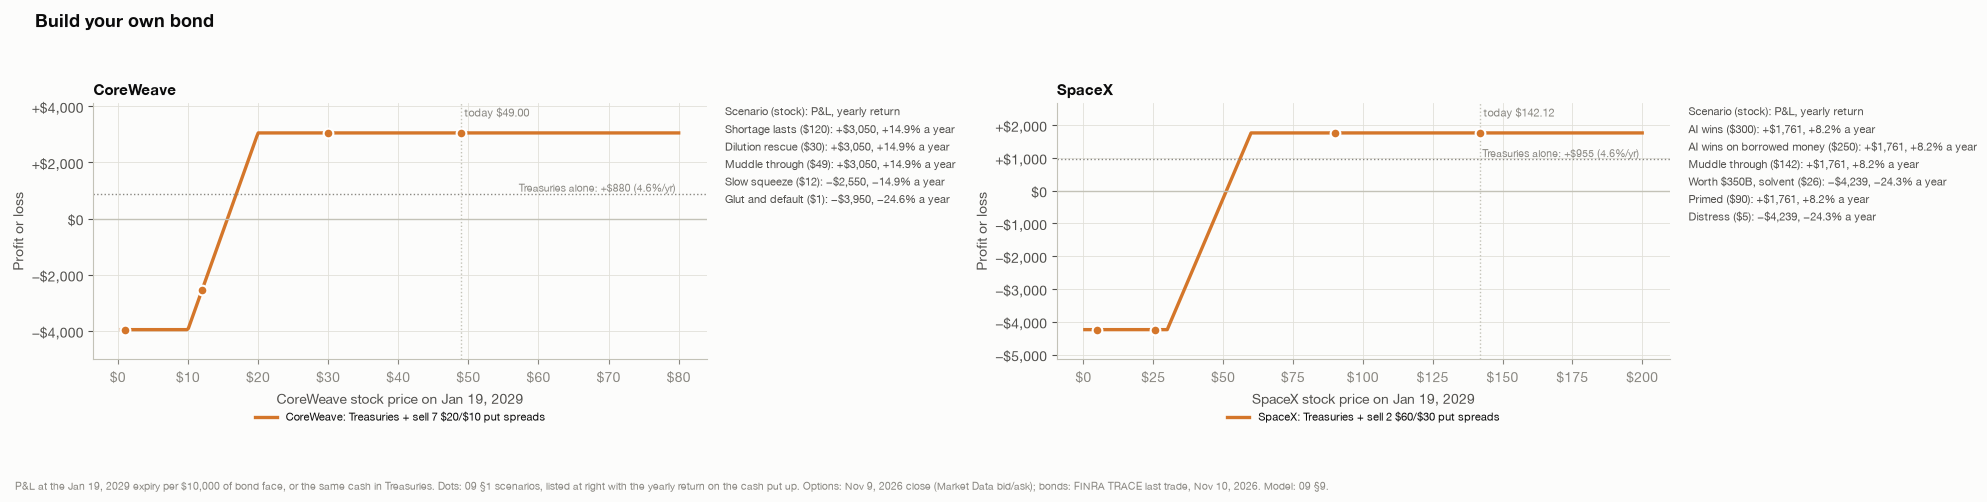

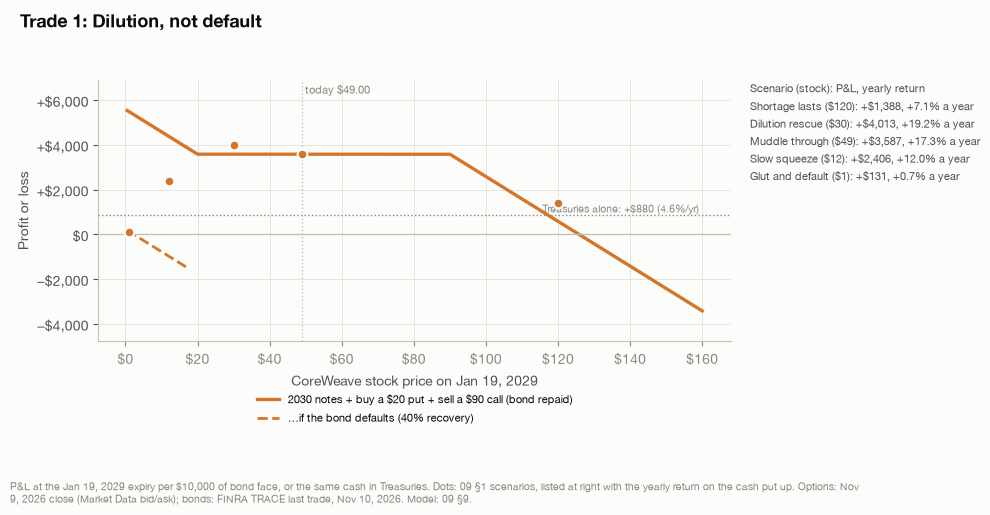

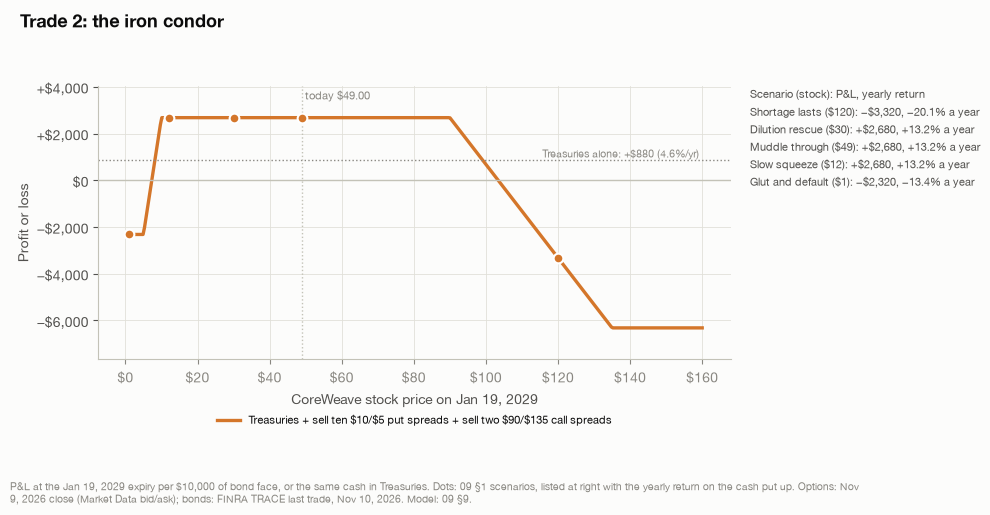

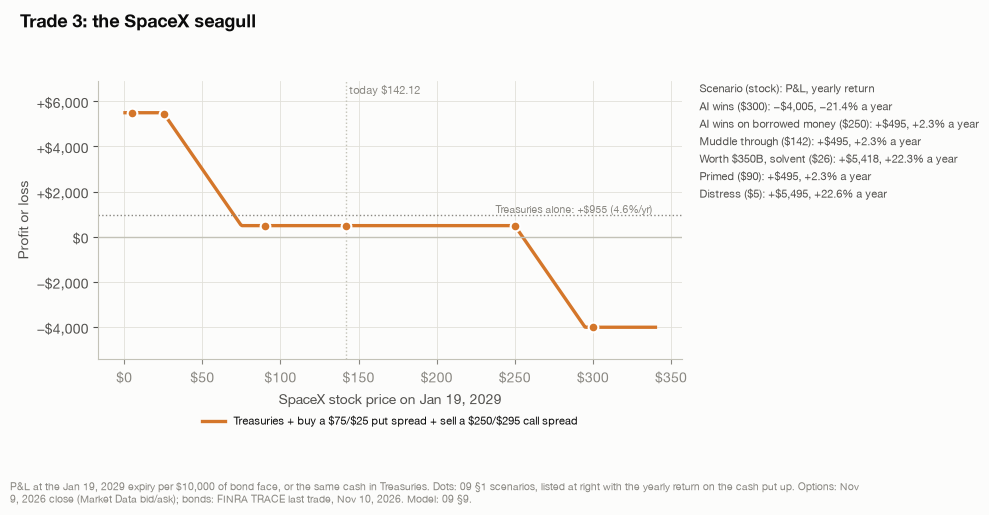

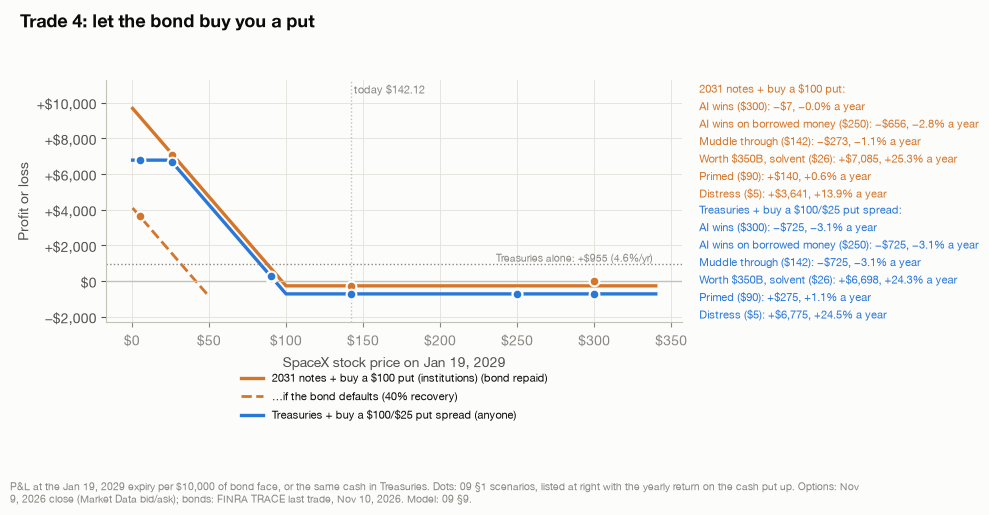

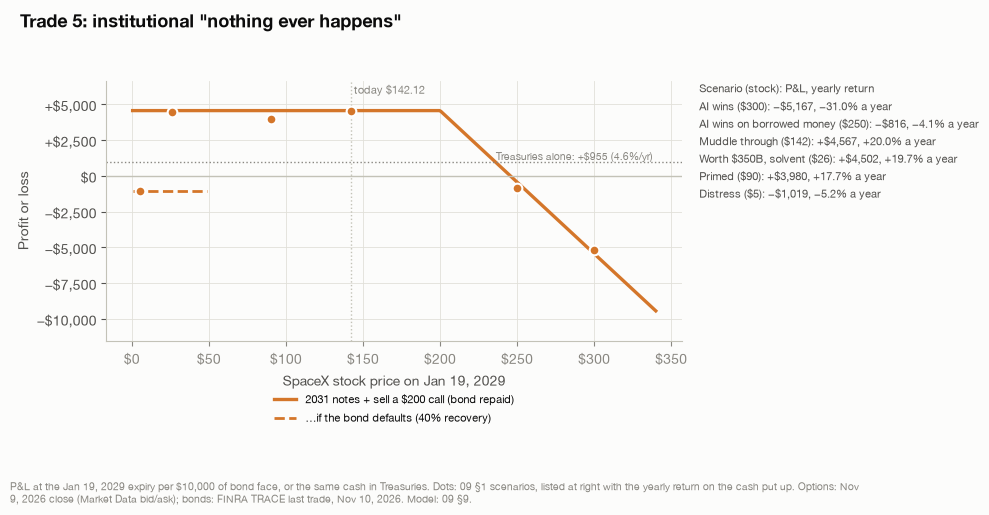

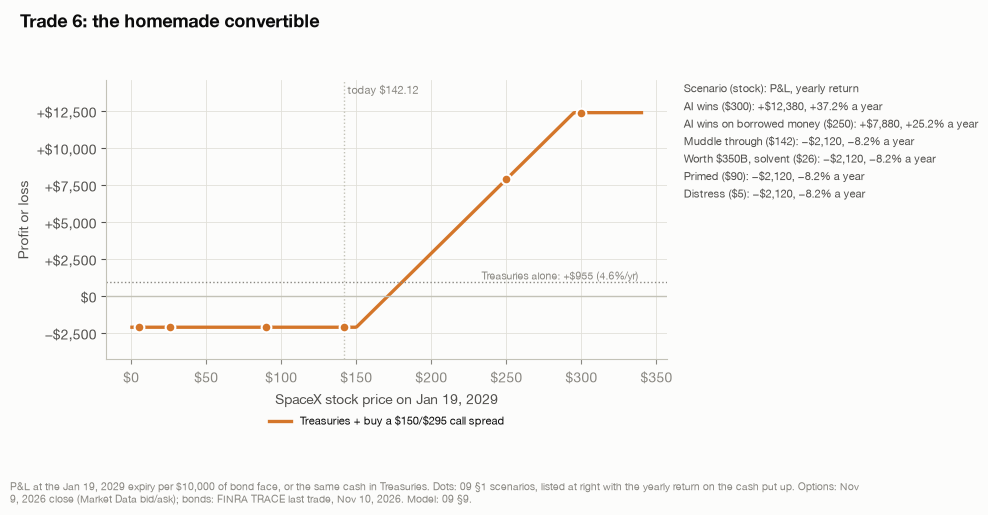

In [18]:
money = mticker.FuncFormatter(lambda v, _: f"{'+' if v > 0 else '−' if v < 0 else ''}${abs(v):,.0f}")
COLORS = [EQUITY, BOND]

def post_chart(key):
    """One payoff chart per post trade: P&L at the Jan 2029 expiry vs. the stock price (solid: the bond is repaid;
    dashed: it defaults, drawn only at low prices), with each scenario as a dot labelled with its yearly return."""
    title, t0, variants, xmax = POST[key]
    panels = [[v] for v in variants] if key == 'build' else [variants]
    fig, axes = plt.subplots(1, len(panels), figsize=(10 * len(panels), 4.8), squeeze=False)
    for ax, vs in zip(axes[0], panels):
        for i, v in enumerate(vs):
            label, bond, legs = v[:3]; t = v[3] if len(v) > 3 else t0; xm = v[4] if len(v) > 4 else xmax
            S = np.linspace(0.5, xm, 400)
            alive = [post_pnl(t, bond, legs, {'stock': s, 'default': False, 'y': {bond: NOW_Y[bond]} if bond else {}}) for s in S]
            ax.plot(S, alive, color=COLORS[i], lw=2.4, label=label + (' (bond repaid)' if bond else ''))
            if bond:
                Sd = S[S < 0.35 * SPOT[t]]
                ax.plot(Sd, [post_pnl(t, bond, legs, {'stock': s, 'default': True}) for s in Sd], color=COLORS[i], lw=2, ls='--',
                        label='…if the bond defaults (40% recovery)')
            cap = capital(t, bond, legs)
            box = [f'{label.split(" (")[0] if len(vs) > 1 else "At expiry"}:' if len(vs) > 1 else 'Scenario (stock): P&L, yearly return']
            for scn, sc in SCEN[t].items():
                p = post_pnl(t, bond, legs, sc)
                if sc['stock'] <= xm:
                    ax.plot(sc['stock'], p, 'o', ms=7, color=COLORS[i], mec='white', mew=1.5, zorder=4)
                box.append(f"{scn} (${sc['stock']:,.0f}): {'+' if p >= 0 else '−'}${abs(p):,.0f}, {'+' if ann(p, cap) >= 0 else '−'}{abs(ann(p, cap)):.1%} a year")
            ax.text(1.03, 1 - 0.5 * i, '\n'.join(box), transform=ax.transAxes, va='top', ha='left', fontsize=8, color=COLORS[i] if len(vs) > 1 else INK2, linespacing=1.35)
        ax.axhline(0, color=AXIS, lw=1)
        ax.axhline(cash_leg(CASH[t]), color=MUTED, lw=1, ls=':')
        ax.text(xm, cash_leg(CASH[t]), f'Treasuries alone: +${cash_leg(CASH[t]):,.0f} ({100 * TSY_Y:.1f}%/yr) ', fontsize=7.5, color=MUTED, ha='right', va='bottom')
        ax.axvline(SPOT[t], color=AXIS, lw=1, ls=':')
        ax.text(SPOT[t], 0.99, f' today ${SPOT[t]:.2f}', transform=ax.get_xaxis_transform(), fontsize=8, color=MUTED, va='top')
        ax.set_xlabel(f'{"CoreWeave" if t == "CRWV" else "SpaceX"} stock price on Jan 19, 2029')
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'${v:,.0f}'))
        ax.yaxis.set_major_formatter(money)
        ax.set_ylabel('Profit or loss')
        ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.16), fontsize=8, frameon=False, ncol=1)
        ax.margins(y=0.15)
        if key == 'build': ax.set_title(vs[0][0].split(':')[0], loc='left', fontsize=11)
    fig.suptitle(title, x=0.02, ha='left', fontsize=13, fontweight='bold')
    source_note(fig, f'P&L at the Jan 19, 2029 expiry per $10,000 of bond face, or the same cash in Treasuries. Dots: 09 §1 scenarios, listed at right with the yearly '
                     f'return on the cash put up.\n' f'Options: {AS_OF:%b %-d, %Y} close (Market Data bid/ask); bonds: FINRA TRACE last trade, {BOND_DATE:%b %-d, %Y}. Model: 09 §9.')
    fig.tight_layout(rect=(0, 0.04, 1, 0.94))
    fig.savefig(CHARTS / f'09_post_{key}.png', dpi=200, bbox_inches='tight')
    plt.show()

for key in POST: post_chart(key)
post_tr.pivot_table(index=['trade', 'version'], columns='scenario', values='yearly return', sort=False).style.format('{:+.1%}', na_rep='')


**What this shows** (`charts/09_post_build.png`, `09_post_trade1.png` … `09_post_trade6.png`, and the tables above; yearly return on the cash put up, if nothing changes, vs. 4.6% on Treasuries):
- **Build your own bond:**
  - CoreWeave: Treasuries + seven sold $20/$10 put spreads earn ~14.9% a year above $20, about the bond's 14.6% (14.0% held to Jan 2029). They break even at ~$16, which the options market gives ~44% odds. A bet on the stock, not only on default.
  - SpaceX: two sold $60/$30 put spreads earn ~8.2%, *more* than the bond's 7.2%, but only by insuring against a ~60% fall (break-even ~$51, ~22% odds). The deep spreads that only lose in a default pay ~5% (§2).
- **Trade 1** (2030 notes + $20 put − $90 call): ~17% a year if nothing changes, ~19% in a dilution rescue, ~+0.7% in a default. It loses money above ~$126 (~13% odds) with the bond priced at today's yield, and without limit above that.
- **Trade 2** (iron condor): ~13% a year anywhere between ~$10 and $90; break-evens ~$7 and ~$103; worst case ~−$6,300 above $135.
- **Trade 3** (seagull): ~2.3% a year if nothing changes. The options cost ~$460 of the ~$955 Treasury interest. ~22% a year at $350B or in distress; worst ~−$4,000 above $295.
- **Trade 4** (bond + $100 put, or Treasuries + $100/$25 put spread): −1 to −3% a year if nothing changes, worst ~−$725; ~24–25% a year at $350B. In distress the Treasury version wins (~+$6,800 vs. ~+$3,600).
- **Trade 5** (bond − $200 call): ~20% a year if nothing changes, vs. the bond's ~7.0% to Jan 2029. Loses above ~$246 (~17% odds), without limit.
- **Trade 6** (Treasuries + $150/$295 call spread): −8.2% a year below $150; ~37% a year at $295 and above; break-even ~$171 (~34% odds).
- **Reading the charts:** for bond trades the solid line assumes the bond is repaid at today's yield, so at very low stock prices it is optimistic; the dashed line is the default case. The dots sit off the solid line where a scenario assumes a different bond yield (e.g. *dilution rescue* prices CoreWeave at 11%).

## Findings, by section

**§1 · Method.**
- Priced at Jan 19, 2029 (the longest listed expiry) under named scenarios, each tied to an earlier notebook.
- Every option leg is a quoted bid/ask (Nov 9 close), and bonds use TRACE last trades (Nov 10).
- Reader versions replace the bond with the same cash in Treasuries, and every sold call with a call spread.

**§2 · Build your own bond** (`09_build_your_own_bond.png`).
- Treasuries + sold deep put spreads earn ~9.5–10% on CoreWeave (vs. 14.6% for the 144A bond), and ~5% on SpaceX (vs. 7.2%, with Treasuries at 4.6%).
- The options market barely charges for SpaceX default insurance, so SpaceX's extra yield isn't for default.

**§3 · "Dilution, not default."**
- Bond + a sold $90 call beats the bond alone except in a boom, and cuts a default from ~−$2,520 to ~−$1,070.
- The iron condor (1R) makes ~$2,700 between $10 and $90, with every loss capped.
- Adding a $20 put (trade 2) makes the bond version positive in all five scenarios. What it still loses to is what the ~15% yield pays for.

**§4 · Betting against CoreWeave; payoffs** (`09_coreweave_trades.png`, `09_coreweave_payoffs.png`).
- Puts (~$1,150 for ~+$3,350 in a default) beat shorting the bond, which costs ~$3,200–4,000 if CoreWeave muddles through.
- The reader's bond earns about two-thirds of the 144A bond's return when CoreWeave survives.
- Exiting a year early leaves sold insurance worth a lot: the reader's bond shows ~+$800 at today's price, not ~+$1,880.

**§5 · SpaceX: solvent but overvalued.**
- Trade 4 is paid ~$1,100 to put on and makes ~$7,500 at $350B. The seagull (4R) makes ~$5,400 there with capped risk, but only ~$500 if nothing changes.
- Trades 5 and 5R never lose more than ~$725, and make ~$6,700–7,100 at $350B. 5R wins in distress.
- Trade 6 earns ~20% a year if nothing changes, but has no reader version.

**§6 · SpaceX bulls; payoffs** (`09_spacex_trades.png`, `09_spacex_payoffs.png`).
- The Treasury convertible (7R) beats the homemade convertible (7) in every scenario, by ~$300 if AI wins and ~$6,700 in distress. A real convertible bundles the same two pieces, paying for the call through a lower coupon.
- Shorting the 2056s to bet on priming doesn't pay, because their coupon eats the gain.

**§7 · How to build it** (`09_how_to_build_it.png`).
- Leg by leg: the bond becomes Treasuries, its default risk becomes sold deep put spreads, and naked options become spreads.
- Each reader trade is 2–5 option orders plus Treasuries, with a known maximum loss. Examples: the iron condor's ~$6,300, the put spread's ~$725.
- A real convertible (CoreWeave's 2033s) is a bond plus a call paid for with ~6.75 points a year of coupon. Ours pays for the call up front.

**§8 · Access.** Every reader version needs only Treasuries and spread-level options approval.

**§9 · The post's trades** (`09_post_*.png`).
- As a yearly return on the cash put up, if nothing changes: CoreWeave build ~14.9% (bond 14.6%), SpaceX build ~8.2% (bond 7.2%), trade 1 ~17.3%, iron condor ~13.2%, seagull ~2.3%, SpaceX put trades −1 to −3%, bond − $200 call ~20.0%, Treasury convertible −8.2%.
- The SpaceX build only beats the bond by insuring against a ~50% fall; the seagull's options eat about half its Treasury interest at these prices.

## Caveats
- **One day's quotes.** Every number moves; CoreWeave fell to $43.65 on Nov 5 and was back at $49 by Nov 9, ahead of its Nov 10 Q3 results.
- **TRACE prices for Nov 10 are each bond's last trade, read from its FINRA page** (FINRA's data service didn't answer direct queries). FINRA shows no yield for the SpaceX 2056s, so it's computed from the price. The options are a day older (Nov 9 close).
- **Model-free odds are rough.** They're read from neighbouring quoted strikes, so wide quotes add noise of a few points.
- **The "a year early" lines assume each option keeps today's volatility.** In a real crash, volatility jumps, which helps bought options and hurts sold ones.
- **Scenario outcomes are assumptions.** Default is placed at the expiry date, with coupons paid until then, which flatters the bond legs. Recovery is 40% (`bonds.csv`); 03 notes it may be lower for CoreWeave.
- **Sizing is illustrative:** one $10,000 bond position (or the same cash in Treasuries) against 1–10 contracts. Different sizes give different trade-offs.
- **Borrow fees, margin, early assignment, and taxes** are simplified or ignored. Sold American-style options can be assigned early, which matters most for the deep sold puts.

## Open items
- [x] Re-priced to the Nov 5 close (Nov 6).
- [x] Re-priced to Nov 9 options / Nov 10 TRACE (Nov 10).
- [ ] Re-price on the day the post goes out. Market Data's free plan is a day behind: set `REFRESH = True`, then add that day's TRACE closes to `data/trade_quotes.csv`.
- [ ] When 2030 LEAPS list (usually around September), re-price trade 1 with options that expire after the June 2030 notes.